# 220260317 Feronia salinity time course sc 291 ~ 294 (new integrated seu 3 object, no suspicious cluster) Cell Oracle output, select important TF genes
# WT-untreated vs fer4-untreated
This runs within the mast Conda environment \
Analyzes the results in 20250509_feronia_salinity_time_course_WT_untreated_fer4_untreated_CellOracle.ipynb

In [2]:
# Check the conda env running, it's important that you're running in the correct conda env
# Don't change anything here
Sys.getenv("CONDA_DEFAULT_ENV")

[1] "mast"

In [3]:
# Change the path to your own directory
rm(list=ls())
setwd("/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster/analysis/tables/TF_gene")


In [4]:
# Load the libraries
# Don't change anything here
suppressMessages(library(tidyverse))
library(RColorBrewer)
library(grid)
library(patchwork)
library(ggvenn)
library(patchwork)
suppressMessages(library(ComplexHeatmap))
suppressMessages(library(Seurat))
suppressMessages(library(circlize))
suppressMessages(library(gprofiler2))
library(tidytext)

In [5]:
# Check the loaded packages and their versions. 
# # Be sure to execute this! It's important for reproducibility and debugging
# Don't change anything here
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Red Hat Enterprise Linux 9.5 (Plow)

Matrix products: default
BLAS/LAPACK: /resnick/groups/NolanLab/cchen/miniconda3/envs/mast/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8           LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] tidytext_0.4.3        gprofiler2_0.2.3      circlize_0.4.16      
 [4] Seurat_5.0.0          SeuratObject_5.2.0    sp_2.2-0             
 [7] ComplexHeatmap_2.22.0 ggvenn_0.1.

Here, we're looking for genes that are both highly important and show changes in their importance under stress or recovery conditions. We also want to determine the direction of change. The genes we’re most interested in are those with higher importance in the experimental group compared to the control group. Therefore, we select only the genes that are ranked as more important in the experimental group.

## Define the selecting function
Here, we're looking for genes that are both highly important and show changes in their importance under stress or recovery conditions. We also want to determine the direction of change. The genes we’re most interested in are those with higher importance in the experimental group compared to the control group. Therefore, we quantify how the gene's importance changes between groups. 

In [37]:
extract_top_genes <- function(gene_score, # Data frame containing centrality scores for each gene. Note that
                              top_genes_number = 100, # Number of top genes to select per cluster/treatment/time point
                              file_tag, # Tag for output file names (e.g., date and study name)
                              metrics = c("degree_centrality_all", "degree_centrality_in", "degree_centrality_out", 
                                          "betweenness_centrality", "closeness_centrality", "eigenvector_centrality"), # Character vector of centrality metrics to analyze
                              comparisons # List of groups to compare rank differences
) {
  cell_types <- unique(gene_score$cell_type) # Get unique cell types
  
  # Initialize a list to store the concatenated data for each cell type
  concatenated_top_genes_df_list <- list()
  concatenated_rank_diff_df_list <- list()
  
  # Loop over each cell type and metric
  for (i in 1:length(cell_types)) { # loop over cell types
    this_celltype <- cell_types[i]
    print(this_celltype)

    # Check if this cell type has less than two unique groups
      unique_groups <- unique(gene_score$group[gene_score$cell_type == this_celltype])
      if (length(unique_groups) < 2) {
        print(paste0("Skipping cell type: ", this_celltype, " (only 1 group present)"))
          # Skip this cell type and move to the next one
          # "Next" skips the current iteration of the loop and moves to the next one. 
          # It doesn’t exit the loop completely, it just skips the rest of the code for the current iteration.
        next  
      }
      
    # Initialize lists for concatenating top genes and rank differences for each cell type
    top_genes_df_list <- list()
    rank_diff_df_list <- list()
    
    for (k in 1:length(metrics)) {  # loop over metrics
      this_metric <- metrics[k]
      print(paste0(this_metric, ": ", this_celltype))
      
      # Subset the genes to each cell type and rank the genes
      sub_gene_score <- gene_score %>%
        filter(cell_type == this_celltype) %>%
        dplyr::select(c(1, 2, 22:24, str_which(string = colnames(.), pattern = this_metric))) %>%
        group_by(cluster) %>% # group by cluster
        mutate(gene_rank = rank(-get(this_metric), ties.method = "min")) %>% # rank genes (higher metric = lower rank)
        ungroup()

      ## Run through each cluster within a cell type
      clusters <- unique(sub_gene_score$cluster)
      top_genes_list <- list()  # Initialize an empty list to store top genes and their ranks
      
      for (j in 1:length(clusters)) {  # loop over clusters
        this_cluster <- clusters[j]
        
        # Filter and get the top genes based on the selected metric
        top_gene <- sub_gene_score %>%
          filter(cluster == this_cluster) %>%  # Keep only rows belonging to the current cluster
          slice_max(order_by = get(this_metric), n = top_genes_number, with_ties = TRUE)   # Select top genes
        
        # Store as a dataframe with gene name and rank
        top_genes_list[[this_cluster]] <- top_gene %>% select(gene, name, cluster,  all_of(this_metric), gene_rank)
        colnames(top_genes_list[[this_cluster]])[4] <- "metric_value"
      }
      
      # dplyr::bind_rows is more convenient than rbind!
      top_genes_df <- bind_rows(top_genes_list) %>% 
        mutate(cell_type = this_celltype, .after = 2) %>% 
        mutate(metric = this_metric, .after = 4)
      
      # Append to the list for concatenation
      top_genes_df_list[[this_metric]] <- top_genes_df
      
      # Write top_genes_df as output table
      #file_name <- paste0(file_tag, "_top", top_genes_number, "_", this_celltype, "_", this_metric, "_selected_genes.txt")
      #file_name <- gsub(x = file_name, pattern = " ", replacement = "_")    
      #write.table(top_genes_df, file_name, sep = "\t", row.names = F, col.names = T, quote = F)
      
      # Extracts only the gene names from each dataframe and unlist it
      unique_genes <- unique(unlist(lapply(top_genes_list, function(df) df$gene))) 
      
      # Subset genes cuz we only want genes among top n in at least 1 cluster
      sub_gene_score_top <- sub_gene_score %>%
        filter(gene %in% unique_genes)
      
      # Initialize an empty list to store the rank differences
      rank_diff_list <- list()
      
      for (p in 1:length(comparisons)) {
        comp <- comparisons[[p]]
        group1 <- comp[1]  # First group in comparison, the experiment group
        group2 <- comp[2]  # Second group in comparison
        
        # Subset for each group
        df1 <- sub_gene_score_top %>% filter(group == group1) %>% select(gene, name, gene_rank)
        df2 <- sub_gene_score_top %>% filter(group == group2) %>% select(gene, name, gene_rank)

        # Check if either df1 or df2 has no rows (i.e., one or both of the groups are missing in this cell type, so skip it)
          if (nrow(df1) == 0 | nrow(df2) == 0) {
            # If either dataframe is empty, skip this comparison. 
            #"Next" skips the current iteration of the loop and moves to the next one. 
            # It doesn’t exit the loop completely, it just skips the rest of the code for the current iteration.
              print(paste0("Skipping comparison: ", group1, " vs ", group2, " (one or both groups have no data)"))
                next
              }
          
        # Merge based on gene name
        merged_df <- inner_join(df1, df2, by = "gene", suffix = c("_1", "_2")) #%>% # Suffix is to tag duplicated columns
           # filter(gene_rank_1 <= top_genes_number | gene_rank_2 <= top_genes_number) # The gene should be ranked top top_genes_number in at least one group (group = cluster here)
        
          
        # Calculate rank difference (group1 rank - group2 rank, i.e., experimental - control)  
        # Lower rank number indicates higher importance  
        # group1 rank - group2 rank < 0 means the gene became more important in group1 (experimental)
        merged_df <- merged_df %>%
          mutate(rank_diff = gene_rank_1 - gene_rank_2) %>%
          mutate(comparison = paste0(group1, "-", group2), .after = 1) %>% 
          arrange(rank_diff) %>% 
          mutate(rank_diff_rank = rank(rank_diff, ties.method = "min")) %>% 
          dplyr::select(-c("name_2")) %>% 
          rename(name = name_1) %>% 
          dplyr::select(c(gene, name, everything()))
        
        # Store in list
        rank_diff_list[[paste0(group1, "-", group2)]] <- merged_df
      }
      
      # dplyr::bind_rows is more convenient than rbind!
      rank_diff_df <- bind_rows(rank_diff_list) %>% 
        mutate(cell_type = this_celltype, .after = 2) %>% 
        mutate(metric = this_metric, .after = 4) %>% 
        arrange(comparison, rank_diff_rank)
      
      # Append to the list for concatenation
      rank_diff_df_list[[this_metric]] <- rank_diff_df
      
      # Write rank_diff_df as output table
      #file_name <- paste0(file_tag, "_top", top_genes_number, "_", this_celltype, "_", "this_metric_change.txt")
      #file_name <- gsub(x = file_name, pattern = " ", replacement = "_")                                     
      #write.table(rank_diff_df, file_name, sep = "\t", row.names = F, col.names = T, quote = F)
    }
    
    # Concatenate all metrics for this cell type
    concatenated_top_genes_df <- bind_rows(top_genes_df_list) %>% 
      mutate(cell_type = this_celltype, .after = 2)
    concatenated_rank_diff_df <- bind_rows(rank_diff_df_list) %>% 
      mutate(cell_type = this_celltype, .after = 2)
    
    # Save concatenated tables
    #concatenated_top_genes_file_name <- paste0(file_tag, "_top", top_genes_number, "_", this_celltype, "_all_metrics_selected_genes.txt")
    #concatenated_rank_diff_file_name <- paste0(file_tag, "_top", top_genes_number, "_", this_celltype, "_all_metrics_selected_genes_change.txt")
    
    #concatenated_top_genes_file_name <- gsub(x = concatenated_top_genes_file_name, pattern = " ", replacement = "_")
    #concatenated_rank_diff_file_name <- gsub(x = concatenated_rank_diff_file_name, pattern = " ", replacement = "_")
    
    #write.table(concatenated_top_genes_df, concatenated_top_genes_file_name, sep = "\t", row.names = F, col.names = T, quote = F)
    #write.table(concatenated_rank_diff_df, concatenated_rank_diff_file_name, sep = "\t", row.names = F, col.names = T, quote = F)
    
    # Add to the list for final concatenation of all cell types
    concatenated_top_genes_df_list[[this_celltype]] <- concatenated_top_genes_df
    concatenated_rank_diff_df_list[[this_celltype]] <- concatenated_rank_diff_df
  }
  
  # Concatenate across all cell types
  final_concatenated_top_genes_df <- bind_rows(concatenated_top_genes_df_list)
  final_concatenated_rank_diff_df <- bind_rows(concatenated_rank_diff_df_list)
  
  # Save final concatenated tables
  final_concatenated_top_genes_file_name <- paste0(file_tag, "_top", top_genes_number, "_all_cell_types_all_metrics_selected_genes.txt")
  final_concatenated_rank_diff_file_name <- paste0(file_tag, "_top", top_genes_number, "_all_cell_types_all_metrics_selected_genes_change.txt")
  
  final_concatenated_top_genes_file_name <- gsub(x = final_concatenated_top_genes_file_name, pattern = " ", replacement = "_")
  final_concatenated_rank_diff_file_name <- gsub(x = final_concatenated_rank_diff_file_name, pattern = " ", replacement = "_")
  
  write.table(final_concatenated_top_genes_df, final_concatenated_top_genes_file_name, sep = "\t", row.names = F, col.names = T, quote = F)
  write.table(final_concatenated_rank_diff_df, final_concatenated_rank_diff_file_name, sep = "\t", row.names = F, col.names = T, quote = F)
}



## Test on 1 cell type crude (can skip)

### Cortex

In [10]:
# Read in the CellOracle output that contains centrality scores for each gene
# Change the file name to yours
gene_score <- read.csv(file = "../../../cortex_rawRNA_celloracle_gene_score_iGRN.csv", header = T)

gene_score$name <- gsub(x = as.character(gene_score$name), pattern = "[[:punct:][:space:][:cntrl:]]", replacement = "")  

In [11]:
# Check the column names
head(gene_score, 3)

,X,name,degree_all,degree_in,degree_out,clustering_coefficient,clustering_coefficient_weighted,degree_centrality_all,degree_centrality_in,degree_centrality_out,⋯,eigenvector_centrality,page_rank,assortative_coefficient,average_path_length,community_random_walk,module,connectivity,participation,role,cluster
,<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
1,AT3G17609,HYH,110,27,83,0.07406172,0.08438714,0.06134969,0.015058561,0.04629113,⋯,0.2792131,0.0005582415,-0.2963191,0.1506004,1,1,3.725113,0.2447934,Connector Hub,Elongation_Cortex_WT_untreated
2,AT4G36990,HSFB1,288,18,270,0.03955262,0.04377745,0.16062465,0.010039041,0.15058561,⋯,0.9515080,0.0004453162,-0.2963191,0.1506004,2,3,7.410416,0.4965489,Connector Hub,Elongation_Cortex_WT_untreated
3,AT3G10800,BZIP28,256,6,250,0.02886865,0.03254866,0.14277747,0.003346347,0.13943112,⋯,0.9246063,0.0004039145,-0.2963191,0.1506004,2,3,7.238977,0.4251386,Connector Hub,Elongation_Cortex_WT_untreated


In [12]:
a = gene_score %>% filter(X == "AT3G13610")

In [13]:
a

X,name,degree_all,degree_in,degree_out,clustering_coefficient,clustering_coefficient_weighted,degree_centrality_all,degree_centrality_in,degree_centrality_out,⋯,eigenvector_centrality,page_rank,assortative_coefficient,average_path_length,community_random_walk,module,connectivity,participation,role,cluster
<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
AT3G13610,F6H1,26,26,0,0.06461538,0.08711596,0.01450084,0.01450084,0,⋯,0.06921955,0.0005570405,-0.2963191,0.15060043,2,1,0.4200551,0.0000000,Ultra peripheral,Elongation_Cortex_WT_untreated
AT3G13610,F6H1,35,35,0,0.03025210,0.04314945,0.01941209,0.01941209,0,⋯,0.06156031,0.0006555613,-0.3001967,0.14089115,1,3,0.8569542,0.1093878,Peripheral,Elongation_Cortex_fer4_untreated
AT3G13610,F6H1,42,42,0,0.03019744,0.04455732,0.02346369,0.02346369,0,⋯,0.16696523,0.0006642321,-0.2325365,0.07894848,18,2,0.9539039,0.2142857,Peripheral,Maturation_Cortex_WT_untreated
AT3G13610,F6H1,76,76,0,0.01508772,0.02268901,0.04465335,0.04465335,0,⋯,0.47517605,0.0014166251,-0.1796767,0.06546903,1,5,1.2463147,0.5107341,Peripheral,Maturation_Cortex_fer4_untreated


In [15]:
clusters <- unique(gene_score$cluster)

In [16]:
clusters

[1] "Elongation_Cortex_WT_untreated"            
[2] "Elongation_Cortex_fer4_untreated"          
[3] "Maturation_Cortex_WT_untreated"            
[4] "Maturation_Cortex_fer4_untreated"          
[5] "Proliferation Domain_Cortex_WT_untreated"  
[6] "Proliferation Domain_Cortex_fer4_untreated"
[7] "Transition Domain_Cortex_WT_untreated"     
[8] "Transition Domain_Cortex_fer4_untreated"

In [17]:
sub(".*((WT|fer4)_.*)", "\\1", clusters)

[1] "WT_untreated"   "fer4_untreated" "WT_untreated"   "fer4_untreated"
[5] "WT_untreated"   "fer4_untreated" "WT_untreated"   "fer4_untreated"

In [18]:
clusters <- sub(".*((WT|fer4)_.*)", "\\1", clusters)
clusters <- unique(clusters)

In [19]:
clusters
length(clusters)

[1] "WT_untreated"   "fer4_untreated"

[1] 2

In [20]:
sub(pattern = ".*((WT|fer4)_.*)", replacement = "\\1", unique(gene_score$cluster))

[1] "WT_untreated"   "fer4_untreated" "WT_untreated"   "fer4_untreated"
[5] "WT_untreated"   "fer4_untreated" "WT_untreated"   "fer4_untreated"

In [21]:
# Add columns named cell_type and group
gene_score <- gene_score %>%
  mutate(
    cell_type = str_remove(cluster, "_(WT|fer4)_.*"),  # Extract cell type
    group = sub(pattern = ".*((WT|fer4)_.*)", replacement = "\\1", cluster) # Extract time points
    )

In [22]:
head(gene_score, 3)

,X,name,degree_all,degree_in,degree_out,clustering_coefficient,clustering_coefficient_weighted,degree_centrality_all,degree_centrality_in,degree_centrality_out,⋯,assortative_coefficient,average_path_length,community_random_walk,module,connectivity,participation,role,cluster,cell_type,group
,<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,AT3G17609,HYH,110,27,83,0.07406172,0.08438714,0.06134969,0.015058561,0.04629113,⋯,-0.2963191,0.1506004,1,1,3.725113,0.2447934,Connector Hub,Elongation_Cortex_WT_untreated,Elongation_Cortex,WT_untreated
2,AT4G36990,HSFB1,288,18,270,0.03955262,0.04377745,0.16062465,0.010039041,0.15058561,⋯,-0.2963191,0.1506004,2,3,7.410416,0.4965489,Connector Hub,Elongation_Cortex_WT_untreated,Elongation_Cortex,WT_untreated
3,AT3G10800,BZIP28,256,6,250,0.02886865,0.03254866,0.14277747,0.003346347,0.13943112,⋯,-0.2963191,0.1506004,2,3,7.238977,0.4251386,Connector Hub,Elongation_Cortex_WT_untreated,Elongation_Cortex,WT_untreated


In [23]:
colnames(gene_score)[1] <- "gene"

In [24]:
unique(gene_score$group)

[1] "WT_untreated"   "fer4_untreated"

In [25]:
unique(gene_score$cell_type)

[1] "Elongation_Cortex"           "Maturation_Cortex"          
[3] "Proliferation Domain_Cortex" "Transition Domain_Cortex"

In [26]:
# The comparisons you want to make
my_comparisons <- list(c("fer4_untreated", "WT_untreated"))

In [27]:
# create the subfolder first
system("mkdir cortex")

# Execute the function
extract_top_genes(gene_score = gene_score, #Data frame containing centrality scores for each gene. Note that
                  top_genes_number = 100, #Number of top genes to select per cluster/treatment/time point
                  file_tag = "./cortex/20250214_cortex", #Tag for output file names (e.g., date and study name)
                  metrics = c("degree_centrality_all", "degree_centrality_in", 
                              "degree_centrality_out", 
                              "betweenness_centrality"), #Character vector of centrality metrics to analyze
                  comparisons = my_comparisons # List of groups to compare rank differences
)

[1] "Elongation_Cortex"
[1] "degree_centrality_all: Elongation_Cortex"
[1] "degree_centrality_in: Elongation_Cortex"
[1] "degree_centrality_out: Elongation_Cortex"
[1] "betweenness_centrality: Elongation_Cortex"
[1] "Maturation_Cortex"
[1] "degree_centrality_all: Maturation_Cortex"
[1] "degree_centrality_in: Maturation_Cortex"
[1] "degree_centrality_out: Maturation_Cortex"
[1] "betweenness_centrality: Maturation_Cortex"
[1] "Proliferation Domain_Cortex"
[1] "degree_centrality_all: Proliferation Domain_Cortex"
[1] "degree_centrality_in: Proliferation Domain_Cortex"
[1] "degree_centrality_out: Proliferation Domain_Cortex"
[1] "betweenness_centrality: Proliferation Domain_Cortex"
[1] "Transition Domain_Cortex"
[1] "degree_centrality_all: Transition Domain_Cortex"
[1] "degree_centrality_in: Transition Domain_Cortex"
[1] "degree_centrality_out: Transition Domain_Cortex"
[1] "betweenness_centrality: Transition Domain_Cortex"


## Run through all cell types

In [38]:
unique_celltype_crude <- c("cortex", 
                           "endodermis",
                           "trichoblast", 
                           "atrichoblast", 
                           "pericycle",
                           "phloem", 
                           "xylem", 
                           "procambium", 
                           "lrc", 
                           "columella")

In [39]:
# Loop over each cell type and run the analysis
for (celltype_crude in unique_celltype_crude) {
  
  # Read the gene_score data file for the current cell type (assuming different files per cell type)
  file_path <- paste0("../../../", celltype_crude, "_rawRNA_celloracle_gene_score_iGRN.csv")
  gene_score <- read.csv(file = file_path, header = T)

  colnames(gene_score)[1] <- "gene"
    
  # The column "name" contains some special characters like ' or ()!!
  # Remove punctuation, whitespace, control chars in the name column, which causes error later
  # Clean the "name" column in gene_score by removing special characters
  # [[:punct:]] matches punctuation marks like !, ?, ', (, ), etc.
  # [[:space:]] matches whitespace characters like space, tab (\t), newline (\n), etc.
  # [[:cntrl:]] matches control characters like carriage return (\r), form feed (\f), etc.
  # gsub() replaces all matches with an empty string ("")
  gene_score$name <- gsub(x = as.character(gene_score$name), pattern = "[[:punct:][:space:][:cntrl:]]", replacement = "")  

  # Some names match multiple genes, so make it unique or will cause problem when merging tables later
  gene_score$name <- paste0(gene_score$gene, "_", gene_score$name) 
  
  # Add columns for cell type and group
  gene_score <- gene_score %>%
  mutate(
    cell_type = str_remove(cluster, "_(WT|fer4)_.*"),  # Extract cell type
    group = sub(pattern = ".*((WT|fer4)_.*)", replacement = "\\1", cluster) # Extract time points
    )

  # Create the subfolder for each cell type
  system(paste("mkdir", celltype_crude))  # Create folder

  # The comparisons you want to make
  # Make sure that the experimental group goes first, and the control goes second!!
  # c(Group1, Group2) Group 1 is experiment group, while Group2 is the control group!!
 my_comparisons <- list(c("fer4_untreated", "WT_untreated"))
  
  # Execute the function for the current cell type
  extract_top_genes(gene_score = gene_score, # Filtered data frame by cell type
                    top_genes_number = 100, # Number of top genes to select per cluster/treatment/time point
                    file_tag = paste0("./", celltype_crude,  "/20260317_feronia_salinity_WT_untreated_fer4_untreated_", celltype_crude), # Tag for output file names
                    metrics = c("degree_centrality_all", "degree_centrality_in", "degree_centrality_out", 
                                "betweenness_centrality"), # Character vector of centrality metrics to analyze
                    comparisons = my_comparisons # List of groups to compare rank differences
  )
}


[1] "Elongation_Cortex"
[1] "degree_centrality_all: Elongation_Cortex"
[1] "degree_centrality_in: Elongation_Cortex"
[1] "degree_centrality_out: Elongation_Cortex"
[1] "betweenness_centrality: Elongation_Cortex"
[1] "Maturation_Cortex"
[1] "degree_centrality_all: Maturation_Cortex"
[1] "degree_centrality_in: Maturation_Cortex"
[1] "degree_centrality_out: Maturation_Cortex"
[1] "betweenness_centrality: Maturation_Cortex"
[1] "Proliferation Domain_Cortex"
[1] "degree_centrality_all: Proliferation Domain_Cortex"
[1] "degree_centrality_in: Proliferation Domain_Cortex"
[1] "degree_centrality_out: Proliferation Domain_Cortex"
[1] "betweenness_centrality: Proliferation Domain_Cortex"
[1] "Transition Domain_Cortex"
[1] "degree_centrality_all: Transition Domain_Cortex"
[1] "degree_centrality_in: Transition Domain_Cortex"
[1] "degree_centrality_out: Transition Domain_Cortex"
[1] "betweenness_centrality: Transition Domain_Cortex"
[1] "Elongation_Endodermis"
[1] "degree_centrality_all: Elongation_

## Pivot result tables wider & quantify rank changes across treatments

In [40]:
# List all directories (major cell types)
cell_types <- list.dirs("./", full.names = TRUE, recursive = FALSE)

In [41]:
cell_types

[1] ".//atrichoblast" ".//columella"    ".//cortex"       ".//endodermis"  
 [5] ".//lrc"          ".//pericycle"    ".//phloem"       ".//procambium"  
 [9] ".//trichoblast"  ".//xylem"

In [42]:
# Treated - Control
my_comparisons <- list(c("fer4_untreated", "WT_untreated"))

In [43]:
# Comparisons
comparisons <- sapply(my_comparisons, function(x) paste(x[1], x[2], sep = "-"))

comparisons
length(comparisons)

[1] "fer4_untreated-WT_untreated"

[1] 1

In [44]:
# Initialize an empty list to store all_tbl for each cell type
all_tbl_list <- list()

# Loop through each cell type directory
for (cell_type in cell_types) {
  # Extract the cell type name (remove "./")
  cell_name <- sub(".//", "", cell_type)
  
  # Construct the file path
  file_path <- paste0(cell_type, "/20260317_feronia_salinity_WT_untreated_fer4_untreated_", cell_name, "_top100_all_cell_types_all_metrics_selected_genes_change.txt")
  
  # Check if the file exists before proceeding
  if (file.exists(file_path)) {
    # Read the file
    long <- read.table(file_path, sep = "\t", header = TRUE)
    long$top_change <- NULL 
    
    
    # Split into separate data frames for each comparison
    c1 <- long %>% filter(comparison == comparisons[1])
    
    # Rename columns with comparison prefixes
    colnames(c1)[6:9] <- paste0(unique(c1$comparison), ": ", colnames(c1)[6:9])

    c1$comparison <- NULL

    
    # Join all comparisons into one table for this cell type
    all_tbl <- c1

    # Add crude cell type column
    all_tbl <- all_tbl %>% 
      mutate(crude_cell_type = cell_name, .before = 3)
      
    # Store the result in the list with the cell type name as the key
    all_tbl_list[[cell_name]] <- all_tbl
  } else {
    warning(paste("File not found for cell type:", cell_name))
  }
}

In [45]:
file_path

[1] ".//xylem/20260317_feronia_salinity_WT_untreated_fer4_untreated_xylem_top100_all_cell_types_all_metrics_selected_genes_change.txt"

In [46]:
# Combine all all_tbl data frames into one
combined_all_tbl <- bind_rows(all_tbl_list)


In [47]:
# View the result
head(combined_all_tbl, 5)

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>
1,AT2G44790,AT2G44790_UCC2,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,53,118,-65,1
2,AT1G19700,AT1G19700_BLH10,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,98,143,-45,2
3,AT1G11260,AT1G11260_STP1,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,44,84,-40,3
4,AT1G01620,AT1G01620_PIP13,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,25,59,-34,4
5,AT3G46280,AT3G46280_AT3G46280,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,25,52,-27,5


In [48]:
colnames(combined_all_tbl)

[1] "gene"                                       
[2] "name"                                       
[3] "crude_cell_type"                            
[4] "cell_type"                                  
[5] "metric"                                     
[6] "fer4_untreated-WT_untreated: gene_rank_1"   
[7] "fer4_untreated-WT_untreated: gene_rank_2"   
[8] "fer4_untreated-WT_untreated: rank_diff"     
[9] "fer4_untreated-WT_untreated: rank_diff_rank"

In [49]:
# I've checked that these NAs are due to the genes not presenting in the raw CellOracle results
# CellOracle only filter links based on statistical significance (p-value < 0.01),  absolute coefficient weight, and keep only the top 20,000 strongest links.
sum(is.na(combined_all_tbl))


[1] 0

In [50]:
nrow(combined_all_tbl)

[1] 28594

In [51]:
# Pivot rank_diff longer so calculate the quantile of each metric
combined_all_tbl_long <- combined_all_tbl %>%
    dplyr::select(1, 2, 3, 4, 5, matches("rank_diff(?!_rank)", perl = TRUE)) %>%
    pivot_longer(6:ncol(.), names_to = "contrast", values_to = "rank_diff")

head(combined_all_tbl_long)

gene,name,crude_cell_type,cell_type,metric,contrast,rank_diff
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>
AT2G44790,AT2G44790_UCC2,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,fer4_untreated-WT_untreated: rank_diff,-65
AT1G19700,AT1G19700_BLH10,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,fer4_untreated-WT_untreated: rank_diff,-45
AT1G11260,AT1G11260_STP1,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,fer4_untreated-WT_untreated: rank_diff,-40
AT1G01620,AT1G01620_PIP13,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,fer4_untreated-WT_untreated: rank_diff,-34
AT3G46280,AT3G46280_AT3G46280,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,fer4_untreated-WT_untreated: rank_diff,-27
AT1G19770,AT1G19770_PUP14,atrichoblast,Elongation_Atrichoblast,degree_centrality_all,fer4_untreated-WT_untreated: rank_diff,-25


In [52]:
# Check the quantile of each metric
metric_quantile <- combined_all_tbl_long %>%
    group_by(metric) %>%
    summarise(min = min(rank_diff, na.rm = T),
              max = max(rank_diff, na.rm = T),
              median = median(rank_diff, na.rm=T))

In [54]:
# The metrics have very different max/min values, so need to process them separately
metric_quantile

metric,min,max,median
<chr>,<int>,<int>,<dbl>
betweenness_centrality,-250,254,-5
degree_centrality_all,-1713,1356,0
degree_centrality_in,-1023,816,0
degree_centrality_out,-829,872,0


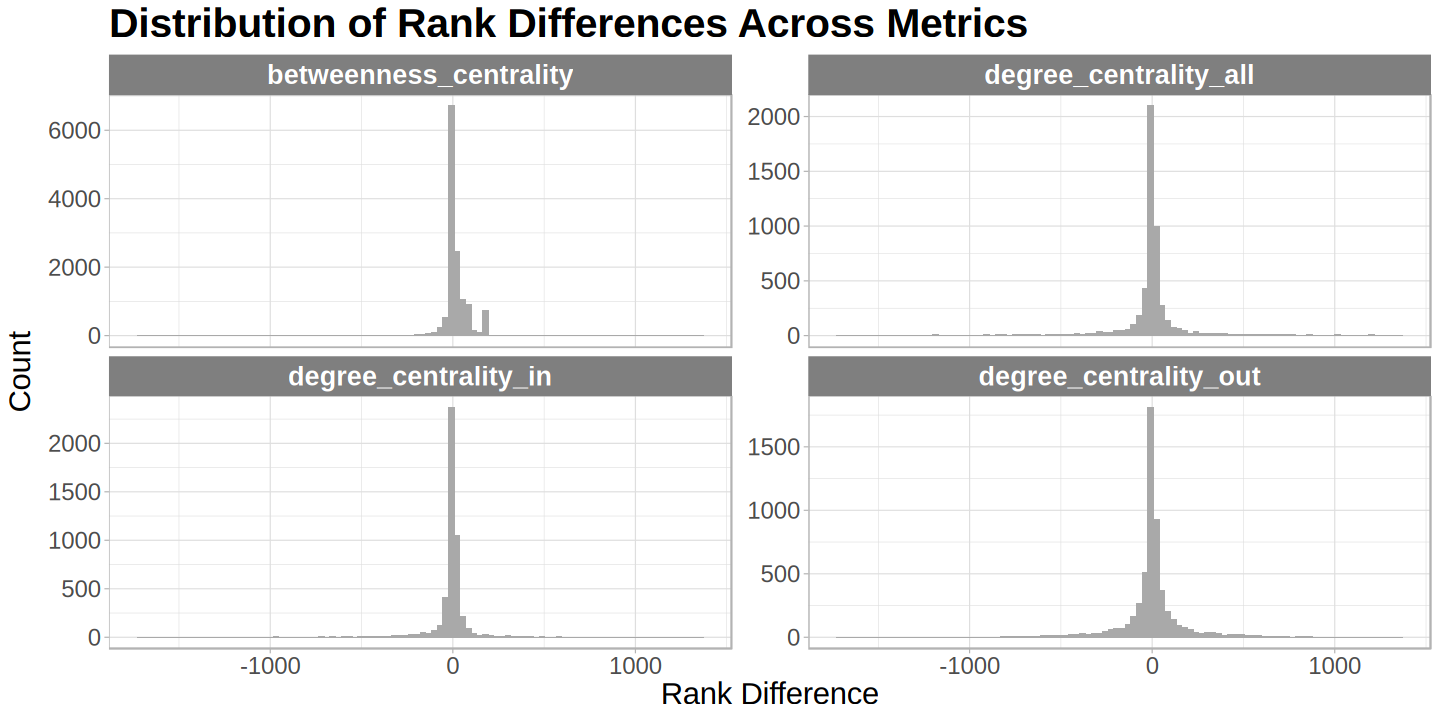

In [55]:
# The metrics have very different distributions, so need to process them separately

options(repr.plot.width=12, repr.plot.height=6)

ggplot(combined_all_tbl_long, aes(x = rank_diff)) +
  geom_histogram(bins = 100, fill = "darkgrey") +
  facet_wrap(. ~ metric, ncol = 2, scales = "free_y") +
  ggtitle("Distribution of Rank Differences Across Metrics") +
  theme_light() +
  theme(
    strip.background = element_rect(fill = "grey50"),
    plot.title = element_text(size = 24, face = "bold"),  # Title size
    axis.title = element_text(size = 18),                 # Axis titles
    axis.text = element_text(size = 14),                  # Axis tick labels
    strip.text = element_text(size = 16, color = "white", face = "bold"),  # Facet labels
  ) +
  labs(x = "Rank Difference", y = "Count")

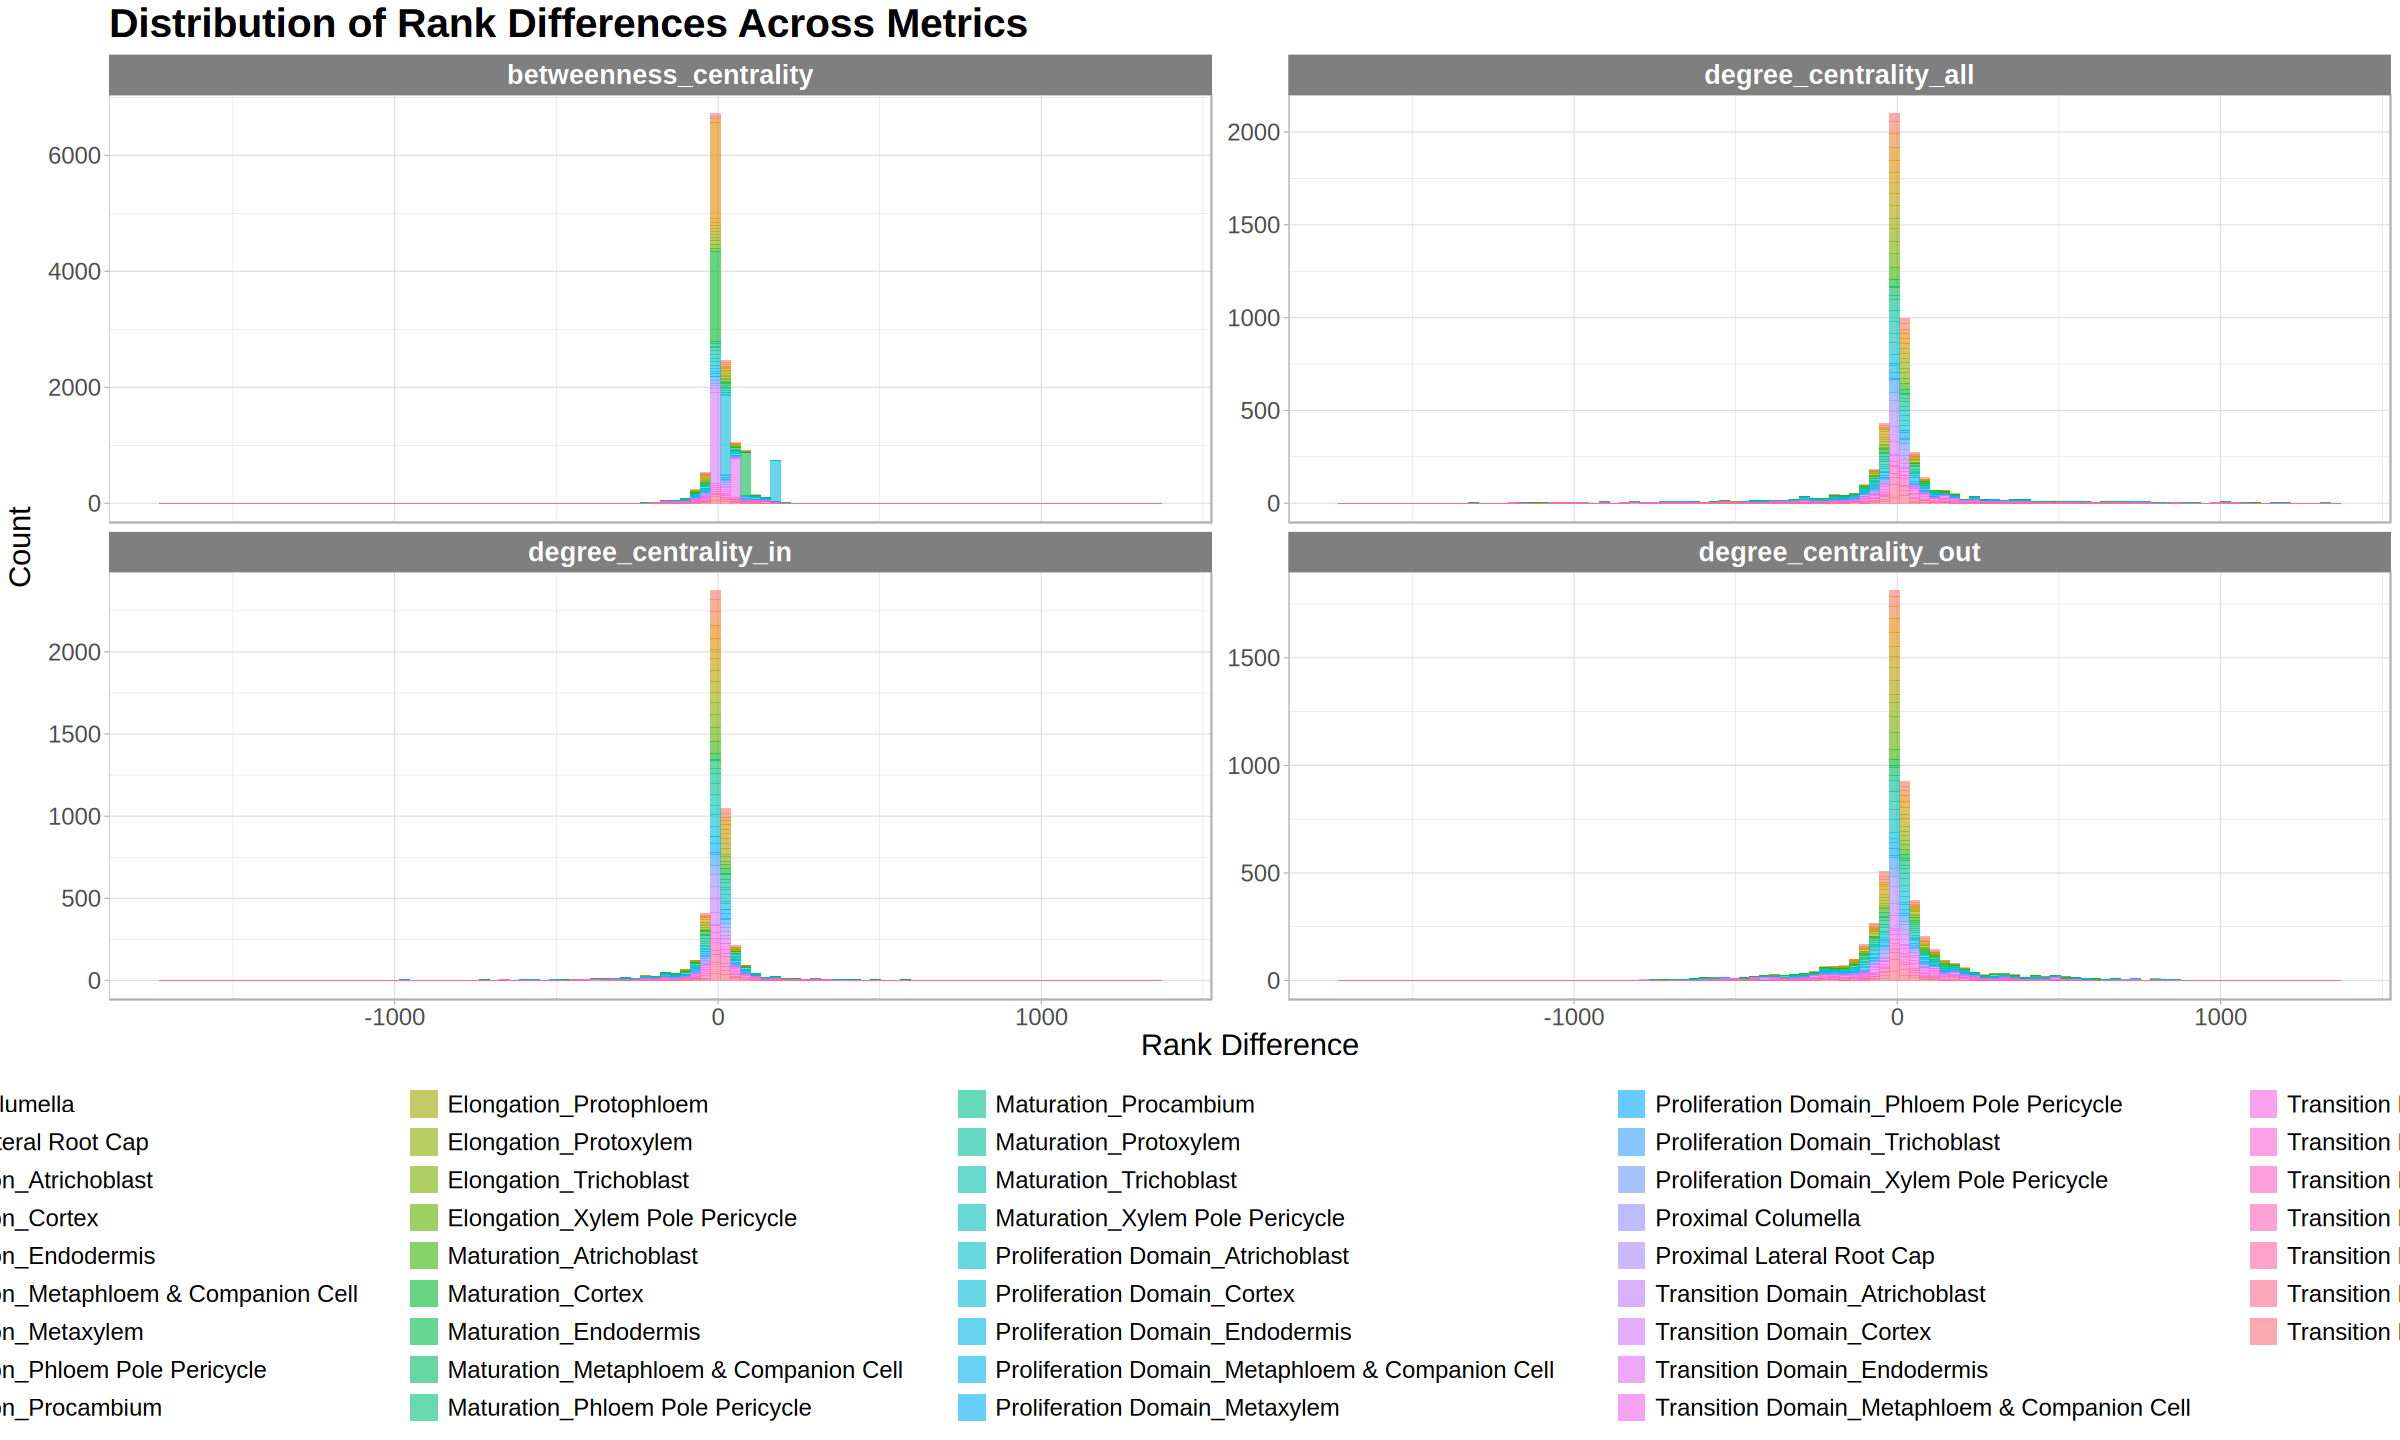

In [56]:
# Each celltype's distribution is highly overlapped, so I can process all cell types together

options(repr.plot.width=20, repr.plot.height=12)

ggplot(combined_all_tbl_long, aes(rank_diff)) +
  geom_histogram(aes(fill = cell_type), bins = 100, alpha = 0.6) +
  facet_wrap(.~metric, ncol = 2, scales = "free_y") +
  theme_light() +
  ggtitle("Distribution of Rank Differences Across Metrics") +
  theme_light() +
  theme(
    strip.background = element_rect(fill = "grey50"),
    plot.title = element_text(size = 24, face = "bold"),  # Title size
    axis.title = element_text(size = 18),                 # Axis titles
    axis.text = element_text(size = 14),                  # Axis tick labels
    strip.text = element_text(size = 16, color = "white", face = "bold"), 
    legend.position = "bottom",
    legend.text = element_text(size = 14),                    # Enlarge legend labels
    legend.title = element_text(size = 16)
  ) +
  labs(x = "Rank Difference", y = "Count")

In [65]:
# Define the top rank_diff values and variance of each metric
metric_threshold <- combined_all_tbl_long %>%
  group_by(metric) %>%
  summarise(
    low = quantile(rank_diff, 0.10, na.rm = TRUE),  # Bottom 10% (10th percentile)
    high = quantile(rank_diff, 0.90, na.rm = TRUE),  # Top 10% (90th percentile)
    std_dev = round(0.05 * sd(rank_diff, na.rm = TRUE)) # 0.05 * std
  )

In [66]:
metric_threshold

metric,low,high,std_dev
<chr>,<dbl>,<dbl>,<dbl>
betweenness_centrality,-15,81.0,3
degree_centrality_all,-96,93.0,11
degree_centrality_in,-55,38.6,6
degree_centrality_out,-123,132.0,8


In [67]:
# Define the top rank_diff values of each metric
# Note that low thresholds are negative values
betweenness_low <- metric_threshold$low[1]
degreeAll_low <- metric_threshold$low[2]
degreeIn_low <- metric_threshold$low[3]
degreeOut_low <- metric_threshold$low[4]

betweenness_high <- metric_threshold$high[1]
degreeAll_high <- metric_threshold$high[2]
degreeIn_high <- metric_threshold$high[3]
degreeOut_high <- metric_threshold$high[4]

# std
betweenness_std <- metric_threshold$std_dev[1]
degreeAll_std <- metric_threshold$std_dev[2]
degreeIn_std <- metric_threshold$std_dev[3]
degreeOut_std <- metric_threshold$std_dev[4]



In [68]:
# Define the metric names and their corresponding thresholds in a named list
low_thresholds <- list(
  "betweenness_centrality" = betweenness_low,
  "degree_centrality_all" = degreeAll_low,
  "degree_centrality_in" = degreeIn_low,
  "degree_centrality_out" = degreeOut_low
)

high_thresholds <- list(
  "betweenness_centrality" = betweenness_high,
  "degree_centrality_all" = degreeAll_high,
  "degree_centrality_in" = degreeIn_high,
  "degree_centrality_out" = degreeOut_high
)


#metric_std <- list(
#  "betweenness_centrality" = betweenness_std,
#  "degree_centrality_all" = degreeAll_std,
#  "degree_centrality_in" = degreeIn_std,
#  "degree_centrality_out" = degreeOut_std
#)

In [69]:
low_thresholds

$betweenness_centrality
10% 
-15 

$degree_centrality_all
10% 
-96 

$degree_centrality_in
10% 
-55 

$degree_centrality_out
 10% 
-123

In [70]:
high_thresholds

$betweenness_centrality
90% 
 81 

$degree_centrality_all
90% 
 93 

$degree_centrality_in
 90% 
38.6 

$degree_centrality_out
90% 
132

In [71]:
#metric_std

In [72]:
names(low_thresholds)

[1] "betweenness_centrality" "degree_centrality_all"  "degree_centrality_in"  
[4] "degree_centrality_out"

In [73]:
names(high_thresholds)

[1] "betweenness_centrality" "degree_centrality_all"  "degree_centrality_in"  
[4] "degree_centrality_out"

In [74]:
unique(combined_all_tbl_long$contrast)

[1] "fer4_untreated-WT_untreated: rank_diff"

In [75]:
all_rank_diff_cols <- unique(combined_all_tbl_long$contrast)
length(all_rank_diff_cols)

[1] 1

In [76]:
# Loop through all metrics
# Initialize an empty list to store results
result_list <- list()

# Loop over each metric
for (metric_name in names(low_thresholds)) {
  # Get the threshold for this metric
  low_threshold <- low_thresholds[[metric_name]]
  high_threshold <- high_thresholds[[metric_name]]
    
  #std_val <- metric_std[[metric_name]]
  
  # Filter rows for this metric and apply labeling
  metric_subset <- combined_all_tbl %>%
    filter(metric == metric_name) %>%
    mutate(Label = case_when(
      # rank diff (negative values) < low threshold
      `fer4_untreated-WT_untreated: rank_diff` < low_threshold ~ "fer4_specific",
     
      # rank diff > high threshold
      `fer4_untreated-WT_untreated: rank_diff` > high_threshold ~ "WT_specific",

        TRUE ~ "None"),

           NA_group_count = rowSums(is.na(select(., all_of(all_rank_diff_cols))))
           
    )
  
  # Store the result in the list
  result_list[[metric_name]] <- metric_subset
}

# Combine all subsets into a single data frame
combined_all_tbl_addLabel <- do.call(rbind, result_list)
rownames(combined_all_tbl_addLabel) <- NULL

In [77]:
nrow(combined_all_tbl_addLabel)

[1] 28594

In [78]:
head(combined_all_tbl_addLabel, 3)

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,NA_group_count
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<dbl>
1,AT3G07340,AT3G07340_BHLH62,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,65,133,-68,1,fer4_specific,0
2,AT1G76890,AT1G76890_GT2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,82,133,-51,2,fer4_specific,0
3,AT3G14230,AT3G14230_RAP22,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,87,127,-40,3,fer4_specific,0


In [80]:
table(combined_all_tbl_addLabel$Label)


fer4_specific          None   WT_specific 
         2846         23104          2644 

In [81]:
unique(combined_all_tbl_addLabel$NA_group_count)

[1] 0

### Add TF table

In [82]:
# Read in the TF table
TF <- read.csv("/resnick/groups/NolanLab/shared_resources/source_files/celloracle_inputs/Kay_TF_thalemine_annotations.csv")
colnames(TF) <- c("gene", "TF_name", "TF_description")

In [83]:
head(TF, 3)

,gene,TF_name,TF_description
,<chr>,<chr>,<chr>
1,AT1G01010,NAC001,NAC domain containing protein 1
2,AT1G01030,NGA3,AP2/B3-like transcriptional factor family protein
3,AT1G01060,LHY,Homeodomain-like superfamily protein


In [84]:
# Add TF column
combined_all_tbl_addLabel_TF <- left_join(combined_all_tbl_addLabel, TF, by = "gene") %>%
   mutate(Is_TF = ifelse(!is.na(TF_name), yes = "Yes", no = "No"), .after = 11)

In [85]:
head(combined_all_tbl_addLabel_TF, 3)

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,AT3G07340,AT3G07340_BHLH62,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,65,133,-68,1,fer4_specific,0,Yes,AT3G07340,basic helix-loop-helix (bHLH) DNA-binding superfamily protein
2,AT1G76890,AT1G76890_GT2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,82,133,-51,2,fer4_specific,0,Yes,GT2,Duplicated homeodomain-like superfamily protein
3,AT3G14230,AT3G14230_RAP22,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,87,127,-40,3,fer4_specific,0,Yes,RAP2.2,related to AP2 2


### Add gene expression logFC table

In [86]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster/analysis/tables/TF_gene"

In [87]:
muscat_res <- read.table("../../../../../.././muscat_result/20250228_salinity_timecourse_useDateT/group_timecelltypeannoLi/fer_4-WT/sig_de.csv", 
                         sep = ",", header = T)


In [88]:
head(muscat_res, 3)

,X,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,⋯,p_val,p_adj.loc,p_adj.glb,contrast,gene.y,non,TF_Name,Description,up_dn_label,clust_up_dn
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1,AT3G51550,Elongation_Cortex,0.164,0.362,290,323,0.00322,0.00164,0.831,⋯,2.48e-234,5.16e-230,1.78e-228,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Cortex_Down
2,2,AT3G51550,Elongation_Phloem Pole Pericycle,0.000,0.267,173,169,0.00000,0.00305,0.711,⋯,6.58e-190,1.36e-185,2.36e-184,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Phloem Pole Pericycle_Down
3,3,AT3G51550,Elongation_Trichoblast,0.000,1.690,231,295,0.00000,0.01380,0.919,⋯,4.02e-173,8.39e-169,9.62e-168,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Trichoblast_Down


In [89]:
colnames(muscat_res)

[1] "X"           "gene"        "cluster_id"  "sc_292.cpm"  "sc_294.cpm" 
 [6] "sc_291.cpm"  "sc_293.cpm"  "sc_292.frq"  "sc_294.frq"  "sc_291.frq" 
[11] "sc_293.frq"  "fer_4.frq"   "WT.frq"      "logFC"       "logCPM"     
[16] "F"           "p_val"       "p_adj.loc"   "p_adj.glb"   "contrast"   
[21] "gene.y"      "non"         "TF_Name"     "Description" "up_dn_label"
[26] "clust_up_dn"

In [90]:
colnames(muscat_res[ , c(2, 3, 18, 14)])

[1] "gene"       "cluster_id" "p_adj.loc"  "logFC"

In [91]:
muscat_res_sel <- muscat_res[ , c(2, 3, 18, 14)]
head(muscat_res_sel, 3)

,gene,cluster_id,p_adj.loc,logFC
,<chr>,<chr>,<dbl>,<dbl>
1,AT3G51550,Elongation_Cortex,5.16e-230,-10.00
2,AT3G51550,Elongation_Phloem Pole Pericycle,1.36e-185,-10.10
3,AT3G51550,Elongation_Trichoblast,8.39e-169,-8.14


In [92]:
colnames(muscat_res_sel) <- c("gene", "cell_type", "p_adj", "log2FC")

In [93]:
head(muscat_res_sel, 3)

,gene,cell_type,p_adj,log2FC
,<chr>,<chr>,<dbl>,<dbl>
1,AT3G51550,Elongation_Cortex,5.16e-230,-10.00
2,AT3G51550,Elongation_Phloem Pole Pericycle,1.36e-185,-10.10
3,AT3G51550,Elongation_Trichoblast,8.39e-169,-8.14


In [94]:
head(combined_all_tbl_addLabel_TF, 1)


,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,AT3G07340,AT3G07340_BHLH62,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,65,133,-68,1,fer4_specific,0,Yes,AT3G07340,basic helix-loop-helix (bHLH) DNA-binding superfamily protein


In [95]:
# Join combined_all_tbl_addLabel_TF with logFC table
combined_all_tbl_addLabel_TF_GE <- left_join(combined_all_tbl_addLabel_TF, muscat_res_sel, 
                                            by = c("gene", "cell_type")) %>%
                                   relocate(c(log2FC, p_adj), .after = Label)
head(combined_all_tbl_addLabel_TF_GE)

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,log2FC,p_adj,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
1,AT3G07340,AT3G07340_BHLH62,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,65,133,-68,1,fer4_specific,0.0365,0.992,0,Yes,AT3G07340,basic helix-loop-helix (bHLH) DNA-binding superfamily protein
2,AT1G76890,AT1G76890_GT2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,82,133,-51,2,fer4_specific,0.0846,0.959,0,Yes,GT2,Duplicated homeodomain-like superfamily protein
3,AT3G14230,AT3G14230_RAP22,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,87,127,-40,3,fer4_specific,0.5140,0.527,0,Yes,RAP2.2,related to AP2 2
4,AT1G79840,AT1G79840_GL2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,94,133,-39,4,fer4_specific,0.1260,0.936,0,Yes,GL2,HD-ZIP IV family of homeobox-leucine zipper protein with lipid-binding START domain-containing protein
5,AT1G32150,AT1G32150_BZIP68,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,76,115,-39,4,fer4_specific,-0.0569,0.983,0,Yes,bZIP68,basic region/leucine zipper transcription factor 68
6,AT5G25810,AT5G25810_TINY,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,97,133,-36,6,fer4_specific,-0.3630,0.892,0,Yes,tny,Integrase-type DNA-binding superfamily protein


In [96]:
# Some genes in combined_all_tbl_addLabel_TF_GE aren't in muscat_res_sel
length(setdiff(unique(muscat_res_sel$gene), unique(combined_all_tbl_addLabel_TF_GE$gene)))
length(setdiff(unique(combined_all_tbl_addLabel_TF_GE$gene), unique(muscat_res_sel$gene)))

[1] 19552

[1] 46

In [97]:
nrow(combined_all_tbl_addLabel_TF_GE)
ncol(combined_all_tbl_addLabel_TF_GE)

[1] 28594

[1] 16

In [98]:
log2(1.5)

[1] 0.5849625

In [99]:
# DE label
# Threshold based on log2(1.5), which is 1.5FC
combined_all_tbl_addLabel_TF_GE <- combined_all_tbl_addLabel_TF_GE %>%
   mutate(.after = p_adj,
          DE_label = ifelse(p_adj < 0.05 & abs(log2FC) > log2(1.5), yes = "DE", no = "None"))

In [100]:
head(combined_all_tbl_addLabel_TF_GE, 3)

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,log2FC,p_adj,DE_label,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,AT3G07340,AT3G07340_BHLH62,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,65,133,-68,1,fer4_specific,0.0365,0.992,None,0,Yes,AT3G07340,basic helix-loop-helix (bHLH) DNA-binding superfamily protein
2,AT1G76890,AT1G76890_GT2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,82,133,-51,2,fer4_specific,0.0846,0.959,None,0,Yes,GT2,Duplicated homeodomain-like superfamily protein
3,AT3G14230,AT3G14230_RAP22,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,87,127,-40,3,fer4_specific,0.5140,0.527,None,0,Yes,RAP2.2,related to AP2 2


In [101]:
# Add the counts of the gene being stress/recovery-specific or stable-ranking
# Count how often each gene has each label
label_counts <- combined_all_tbl_addLabel_TF_GE %>%
  group_by(gene, metric) %>%
  summarize(
    fer4_specific_count = sum(Label == "fer4_specific"),
    WT_specific_count = sum(Label == "WT_specific"),
    .groups = "drop"
  )

In [102]:
head(label_counts)

gene,metric,fer4_specific_count,WT_specific_count
<chr>,<chr>,<int>,<int>
AT1G01010,betweenness_centrality,0,1
AT1G01030,betweenness_centrality,0,0
AT1G01060,betweenness_centrality,0,0
AT1G01060,degree_centrality_all,0,1
AT1G01060,degree_centrality_out,2,0
AT1G01260,betweenness_centrality,0,1


In [103]:
# Join back to the main table
combined_all_tbl_addLabel_TF_GE <- combined_all_tbl_addLabel_TF_GE %>%
  left_join(label_counts, by = c("gene", "metric"))


In [104]:
combined_all_tbl_addLabel_TF_GE <- combined_all_tbl_addLabel_TF_GE %>%
   relocate(c(fer4_specific_count, WT_specific_count), .after = Label)

In [105]:
head(combined_all_tbl_addLabel_TF_GE)

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,fer4_specific_count,WT_specific_count,log2FC,p_adj,DE_label,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,AT3G07340,AT3G07340_BHLH62,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,65,133,-68,1,fer4_specific,2,1,0.0365,0.992,None,0,Yes,AT3G07340,basic helix-loop-helix (bHLH) DNA-binding superfamily protein
2,AT1G76890,AT1G76890_GT2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,82,133,-51,2,fer4_specific,1,3,0.0846,0.959,None,0,Yes,GT2,Duplicated homeodomain-like superfamily protein
3,AT3G14230,AT3G14230_RAP22,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,87,127,-40,3,fer4_specific,3,1,0.5140,0.527,None,0,Yes,RAP2.2,related to AP2 2
4,AT1G79840,AT1G79840_GL2,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,94,133,-39,4,fer4_specific,4,0,0.1260,0.936,None,0,Yes,GL2,HD-ZIP IV family of homeobox-leucine zipper protein with lipid-binding START domain-containing protein
5,AT1G32150,AT1G32150_BZIP68,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,76,115,-39,4,fer4_specific,7,1,-0.0569,0.983,None,0,Yes,bZIP68,basic region/leucine zipper transcription factor 68
6,AT5G25810,AT5G25810_TINY,atrichoblast,Elongation_Atrichoblast,betweenness_centrality,97,133,-36,6,fer4_specific,1,1,-0.3630,0.892,None,0,Yes,tny,Integrase-type DNA-binding superfamily protein


In [106]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster/analysis/tables/TF_gene"

In [108]:
# Save table
#write.table(combined_all_tbl_addLabel_TF_GE, 
#           "20260317_feronia_salinity_WT_untreated_fer4_untreated_CellOracle_all_metrics_rank_change_wide_TF_GE.txt",
 #          sep = "\t", row.names = F, col.names = T)

### Interesting TFs (fer4_specific)

In [109]:
# Read in the table
combined_all_tbl_addLabel_TF_GE <- read.table(
    "20260317_feronia_salinity_WT_untreated_fer4_untreated_CellOracle_all_metrics_rank_change_wide_TF_GE.txt",
    sep = "\t", header = T, check.names = FALSE
)

In [110]:
# Now we have all data combined: celloracle importance ranking, gene expression DE, marker, TF
fer4_specific_TF <- combined_all_tbl_addLabel_TF_GE %>%
                filter(metric == "degree_centrality_out" & 
                       Is_TF == "Yes" &
                       Label == "fer4_specific") %>%
                arrange(cell_type, desc(log2FC))

In [111]:
head(fer4_specific_TF, 3)
print(paste0("nrow: ", nrow(fer4_specific_TF)))
print(paste0("unique cell type: ", n_distinct(fer4_specific_TF$cell_type)))
print(paste0("unique genes: ", n_distinct(fer4_specific_TF$gene)))
fer4_specific_TF %>% group_by(cell_type) %>% count() %>% arrange(desc(n))

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,fer4_specific_count,WT_specific_count,log2FC,p_adj,DE_label,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>
1,AT3G50410,AT3G50410_DOF34,columella,Distal Columella,degree_centrality_out,61,286,-225,8,fer4_specific,2,0,3.53,0.944,None,0,Yes,OBP1,OBF binding protein 1
2,AT3G50700,AT3G50700_GAF1,columella,Distal Columella,degree_centrality_out,82,878,-796,1,fer4_specific,3,1,3.24,0.944,None,0,Yes,IDD2,indeterminate(ID)-domain 2
3,AT5G38860,AT5G38860_BIM3,columella,Distal Columella,degree_centrality_out,90,323,-233,7,fer4_specific,1,2,1.10,0.944,None,0,Yes,BIM3,BES1-interacting Myc-like protein 3


[1] "nrow: 552"
[1] "unique cell type: 39"
[1] "unique genes: 343"


cell_type,n
<chr>,<int>
Proliferation Domain_Endodermis,61
Maturation_Endodermis,52
Transition Domain_Endodermis,51
Transition Domain_Protophloem,36
Transition Domain_Phloem Pole Pericycle,33
Transition Domain_Metaphloem & Companion Cell,28
Maturation_Phloem Pole Pericycle,25
Transition Domain_Metaxylem,25
Transition Domain_Procambium,18


In [112]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster/analysis/tables/TF_gene"

In [113]:
#write.table(fer4_specific_TF, 
#            "20260317_feronia_salinity_WT_untreated_fer4_untreated_CellOracle_fer4_specific_TF.txt",
#            sep = "\t", quote = T, row.names = F, col.names = T)


### Interesting TFs (WT_specific)

In [114]:
# Now we have all data combined: celloracle importance ranking, gene expression DE, marker, TF
WT_specific_TF <- combined_all_tbl_addLabel_TF_GE %>%
                filter(metric == "degree_centrality_out" & 
                       Is_TF == "Yes" &
                       Label == "WT_specific") %>%
                arrange(cell_type, desc(log2FC))

In [116]:
head(WT_specific_TF, 3)
print(paste0("nrow: ", nrow(WT_specific_TF)))
print(paste0("unique cell type: ", n_distinct(WT_specific_TF$cell_type)))
print(paste0("unique genes: ", n_distinct(WT_specific_TF$gene)))
WT_specific_TF %>% group_by(cell_type) %>% count() %>% arrange(desc(n))

,gene,name,crude_cell_type,cell_type,metric,fer4_untreated-WT_untreated: gene_rank_1,fer4_untreated-WT_untreated: gene_rank_2,fer4_untreated-WT_untreated: rank_diff,fer4_untreated-WT_untreated: rank_diff_rank,Label,fer4_specific_count,WT_specific_count,log2FC,p_adj,DE_label,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<int>,<chr>,<chr>,<chr>
1,AT4G18170,AT4G18170_WRKY28,columella,Distal Columella,degree_centrality_out,384,90,294,134,WT_specific,1,1,0.9730,0.369,None,0,Yes,WRKY28,WRKY DNA-binding protein 28
2,AT4G02020,AT4G02020_EZA1,columella,Distal Columella,degree_centrality_out,180,27,153,128,WT_specific,1,3,0.1270,0.944,None,0,Yes,SWN,SET domain-containing protein
3,AT2G42300,AT2G42300_BHLH48,columella,Distal Columella,degree_centrality_out,217,51,166,129,WT_specific,1,1,0.0941,0.944,None,0,Yes,AT2G42300,basic helix-loop-helix (bHLH) DNA-binding superfamily protein


[1] "nrow: 553"
[1] "unique cell type: 38"
[1] "unique genes: 355"


cell_type,n
<chr>,<int>
Transition Domain_Endodermis,57
Proliferation Domain_Endodermis,53
Maturation_Endodermis,51
Transition Domain_Protophloem,46
Proliferation Domain_Phloem Pole Pericycle,37
Maturation_Phloem Pole Pericycle,26
Transition Domain_Phloem Pole Pericycle,22
Transition Domain_Metaphloem & Companion Cell,21
Proliferation Domain_Xylem Pole Pericycle,20


In [117]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster/analysis/tables/TF_gene"

In [119]:
#write.table(WT_specific_TF, 
#           "20260317_feronia_salinity_WT_untreated_fer4_untreated_CellOracle_WT_specific_TF.txt",
#            sep = "\t", quote = T, row.names = F, col.names = T)


#### Plot the gene expression UMAP of interesting genes by time point (Not used yet)

In [92]:
# future.globals.maxSize sets the maximum size (in bytes) for global variables in the future package during parallel processing.  
 options(future.globals.maxSize = 100 * 1024^3) 

In [92]:
# The function to read Seurat object
# This is specifically for reading Seurat 3/4 objects in a Seurat 5 env
# Don't change anything here
read_seu <- function(dir) {
  seu <- readRDS(dir)
  seu@assays$spliced_RNA <- NULL
  seu@assays$spliced_SCT <- NULL
  seu@assays$unspliced_RNA <- NULL
  seu@assays$unspliced_SCT <- NULL
  seu <- suppressWarnings(suppressMessages(UpdateSlots(seu)))
  seu <- suppressWarnings(suppressMessages(UpdateSeuratObject(seu)))
  return(seu)
}

In [93]:
rc.integrated = read_seu("/resnick/groups/NolanLab/shared_resources/annotated_objects/rds/integrated/rc.integrated_13S_mannitol_seu3_20220513.rds")


In [94]:
my_samples <- c("sc_37", "sc_38", "sc_39", "sc_40",
                "sc_41", "sc_42", "tnm1", "tnm2",
                "tnw1", "tnw2")

In [95]:
rc.integrated <- subset(rc.integrated, 
                        subset = orig.ident %in% my_samples)

In [96]:
table(rc.integrated$orig.ident)


sc_37 sc_38 sc_39 sc_40 sc_41 sc_42  tnm1  tnm2  tnw1  tnw2 
 5870  5327  5686  7284  3478  7022  2846  2788  4887  3938 

In [97]:
rc.integrated@meta.data$Treatment <- case_when(
  rc.integrated$orig.ident == "sc_37" ~ "WT_0",
  rc.integrated$orig.ident == "sc_38" ~ "WT_24man",
  rc.integrated$orig.ident == "sc_39" ~ "WT_24man_4rec",
  rc.integrated$orig.ident == "sc_40" ~ "WT_0",
  rc.integrated$orig.ident == "sc_41" ~ "WT_24man",
  rc.integrated$orig.ident == "sc_42" ~ "WT_24man_4rec",
  rc.integrated$orig.ident == "tnm1" ~ "WT_4man",
  rc.integrated$orig.ident == "tnm2" ~ "WT_4man",
  rc.integrated$orig.ident == "tnw1" ~ "WT_0",
  rc.integrated$orig.ident == "tnw2" ~ "WT_0",
)

In [98]:
table(rc.integrated$orig.ident, rc.integrated$Treatment)

       
        WT_0 WT_24man WT_24man_4rec WT_4man
  sc_37 5870        0             0       0
  sc_38    0     5327             0       0
  sc_39    0        0          5686       0
  sc_40 7284        0             0       0
  sc_41    0     3478             0       0
  sc_42    0        0          7022       0
  tnm1     0        0             0    2846
  tnm2     0        0             0    2788
  tnw1  4887        0             0       0
  tnw2  3938        0             0       0

In [99]:
unique(rc.integrated$Treatment)

[1] "WT_0"          "WT_4man"       "WT_24man"      "WT_24man_4rec"

In [100]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/mannitol/Cell_oracle/CellOracle_outputs/20250207_mannitol_Celloracle/analysis/tables"

In [102]:
# Plot interesting recovery genes
options(repr.plot.width = 24, repr.plot.height = 8)
rc.integrated@meta.data$Treatment <- factor(rc.integrated@meta.data$Treatment, 
                                            levels = c("WT_0", "WT_4man", "WT_24man", "WT_24man_4rec"))

# Extract the unique genes to be plotted
genes_to_plot <- unique(interesting_recovery$gene)

# Set the default assay (SCT in this case)
DefaultAssay(rc.integrated) <- "SCT"

# Define the output directory and create it if it doesn't exist
output_dir <- "../figures/20250214_interesting_gene_UMAP/recovery"
if (!dir.exists(output_dir)) {
  dir.create(output_dir, recursive = TRUE)
}

# Loop over each gene, create the UMAP plot, and save it as a PDF
for (gene in genes_to_plot) {
  message("Plotting gene: ", gene)
  
  p <- FeaturePlot(rc.integrated, 
                   features = gene, 
                   split.by = "Treatment", 
                   #ncol = 2, 
                   pt.size = 1)
  
  # Construct the output filename using the gene name
  filename <- file.path(output_dir, paste0("20250214_mannitol_", gene, "_UMAP.pdf"))
  
  # Open a PDF device, print the plot, and then close the device
  pdf(filename, width = 24, height = 8)
  print(p)
  dev.off()
}


Plotting gene: AT5G38940

Plotting gene: AT4G28940

Plotting gene: AT1G53830

Plotting gene: AT2G16510

Plotting gene: AT1G50010

Plotting gene: AT3G55120

Plotting gene: AT4G20860

Plotting gene: AT4G00430

Plotting gene: AT5G44020

Plotting gene: AT1G29025

Plotting gene: AT3G14690

Plotting gene: AT5G26340

Plotting gene: AT3G15356

Plotting gene: AT5G40890

Plotting gene: AT3G18000

Plotting gene: AT5G05270

Plotting gene: AT5G48580

Plotting gene: AT5G64620

Plotting gene: AT5G08640

Plotting gene: AT3G22230

Plotting gene: AT4G34210

Plotting gene: AT1G47130

Plotting gene: AT1G15930

Plotting gene: AT4G18730

Plotting gene: AT3G28600

Plotting gene: AT5G57560

Plotting gene: AT4G39700

Plotting gene: AT3G13650

Plotting gene: AT3G53600

Plotting gene: AT3G03341

Plotting gene: AT4G33905

Plotting gene: AT4G21310

Plotting gene: AT2G46630

Plotting gene: AT4G33930

Plotting gene: AT5G48060

Plotting gene: AT3G22830

Plotting gene: AT3G50930

Plotting gene: AT5G42650

Plotting gen

In [103]:
# Plot interesting stress genes
options(repr.plot.width = 24, repr.plot.height = 8)
rc.integrated@meta.data$Treatment <- factor(rc.integrated@meta.data$Treatment, 
                                            levels = c("WT_0", "WT_4man", "WT_24man", "WT_24man_4rec"))

# Extract the unique genes to be plotted
genes_to_plot <- unique(interesting_stress$gene)

# Set the default assay (SCT in this case)
DefaultAssay(rc.integrated) <- "SCT"

# Define the output directory and create it if it doesn't exist
output_dir <- "../figures/20250214_interesting_gene_UMAP/stress"
if (!dir.exists(output_dir)) {
  dir.create(output_dir, recursive = TRUE)
}

# Loop over each gene, create the UMAP plot, and save it as a PDF
for (gene in genes_to_plot) {
  message("Plotting gene: ", gene)
  
  p <- FeaturePlot(rc.integrated, 
                   features = gene, 
                   split.by = "Treatment", 
                   #ncol = 2, 
                   pt.size = 1)
  
  # Construct the output filename using the gene name
  filename <- file.path(output_dir, paste0("20250214_mannitol_", gene, "_UMAP.pdf"))
  
  # Open a PDF device, print the plot, and then close the device
  pdf(filename, width = 24, height = 8)
  print(p)
  dev.off()
}


Plotting gene: AT1G65270

Plotting gene: AT1G04980

Plotting gene: AT4G28085

Plotting gene: AT4G21840

Plotting gene: AT1G05340

Plotting gene: AT5G57785

Plotting gene: AT4G09030

Plotting gene: AT3G23390

Plotting gene: AT3G15480

Plotting gene: AT1G11580

Plotting gene: AT2G34300

Plotting gene: AT1G20010

Plotting gene: AT3G03250

Plotting gene: AT5G02960

Plotting gene: AT2G05990

Plotting gene: AT2G21580

Plotting gene: AT5G15150

Plotting gene: AT3G05020

Plotting gene: AT2G47320

Plotting gene: AT5G52920

Plotting gene: AT1G70600

Plotting gene: AT1G67730

Plotting gene: AT5G15230

Plotting gene: AT3G25290

Plotting gene: AT5G48580

Plotting gene: AT3G55360

Plotting gene: AT5G15350

Plotting gene: AT1G05260

Plotting gene: AT5G28540

Plotting gene: AT1G50430

Plotting gene: AT3G28860

Plotting gene: AT5G26780

Plotting gene: AT5G57560

Plotting gene: AT4G15802

Plotting gene: AT2G14890

Plotting gene: AT1G72630

Plotting gene: AT1G19450

Plotting gene: AT1G32210

Plotting gen

### Plot the gene expression of interesting genes by time point (not used yet)


In [146]:
interesting_stress <- read.table("20250425_mannitol_fine_timepoints_celloracle_interesting_stress_enriched_log1.5.txt", 
                                 sep = "\t", header = T)

In [147]:
interesting_recovery$name[str_which(interesting_stress$name, "HHO")]

[1] NA NA NA NA NA NA NA NA NA

In [148]:
interesting_recovery <- read.table("20250425_mannitol_fine_timepoints_celloracle_interesting_recovery_enriched_log1.5.txt", 
                                 sep = "\t", header = T)

In [149]:
head(interesting_stress, 3)

,gene,name,crude_cell_type,cell_type,metric,stress_qvalue,recovery_qvalue,WT_0.5_man.WT_0..gene_rank_1,WT_0.5_man.WT_0..gene_rank_2,WT_0.5_man.WT_0..rank_diff,⋯,Marker_In_n_celltypes_WT_24_rec,CellOracle_label,CellOracle_lenient_label,Stable_ranking_count,Stress_enriched_count,Recovery_enriched_count,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<int>,⋯,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,AT3G01970,AT3G01970_WRKY45,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,5.017587e-64,2.176165e-45,82,183,-101,⋯,0,None,Stress_enriched,0,12,0,0,Yes,WRKY45,WRKY DNA-binding protein 45
2,AT5G26660,AT5G26660_MYB86,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,3.949666e-34,2.487590e-67,70,33,37,⋯,2,None,Stress_enriched,0,11,5,0,Yes,MYB86,myb domain protein 86
3,AT1G74840,AT1G74840_AT1G74840,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,9.795471e-100,1.003612e-24,332,189,143,⋯,0,None,Stress_enriched,1,10,4,0,Yes,AT1G74840,Homeodomain-like superfamily protein


In [150]:
head(interesting_recovery, 3)

,gene,name,crude_cell_type,cell_type,metric,stress_qvalue,recovery_qvalue,WT_0.5_man.WT_0..gene_rank_1,WT_0.5_man.WT_0..gene_rank_2,WT_0.5_man.WT_0..rank_diff,⋯,Marker_In_n_celltypes_WT_24_rec,CellOracle_label,CellOracle_lenient_label,Stable_ranking_count,Stress_enriched_count,Recovery_enriched_count,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<int>,⋯,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,AT5G26660,AT5G26660_MYB86,atrichoblast,Maturation_Atrichoblast,degree_centrality_out,1.190337e-15,2.415963e-76,105,183,-78,⋯,0,None,Recovery_enriched,0,11,5,0,Yes,MYB86,myb domain protein 86
2,AT3G57800,AT3G57800_BHLH60,atrichoblast,Proliferation Domain_Atrichoblast,degree_centrality_out,6.442635e-80,1.521022e-72,212,394,-182,⋯,1,None,Recovery_enriched,1,9,2,0,Yes,AT3G57800,basic helix-loop-helix (bHLH) DNA-binding superfamily protein
3,AT1G36060,AT1G36060_ERF055,atrichoblast,Proliferation Domain_Atrichoblast,degree_centrality_out,6.018952e-141,2.146807e-62,113,103,10,⋯,0,None,Recovery_enriched,0,3,3,0,Yes,AT1G36060,Integrase-type DNA-binding superfamily protein


In [151]:
# Prepare to merge the candidate info
interesting_stress_info <- interesting_stress %>%
   dplyr::select(c(1, 2, 4)) %>%
   mutate(Stress_candidate = "yes", Stress_candidate_group = cell_type)

interesting_recovery_info <- interesting_recovery %>%
   dplyr::select(c(1, 2, 4)) %>%
   mutate(Recovery_candidate = "yes", Recovery_candidate_group = cell_type)

In [152]:
head(interesting_stress_info, 2)
head(interesting_recovery_info, 2)

,gene,name,cell_type,Stress_candidate,Stress_candidate_group
,<chr>,<chr>,<chr>,<chr>,<chr>
1,AT3G01970,AT3G01970_WRKY45,Elongation_Atrichoblast,yes,Elongation_Atrichoblast
2,AT5G26660,AT5G26660_MYB86,Elongation_Atrichoblast,yes,Elongation_Atrichoblast


,gene,name,cell_type,Recovery_candidate,Recovery_candidate_group
,<chr>,<chr>,<chr>,<chr>,<chr>
1,AT5G26660,AT5G26660_MYB86,Maturation_Atrichoblast,yes,Maturation_Atrichoblast
2,AT3G57800,AT3G57800_BHLH60,Proliferation Domain_Atrichoblast,yes,Proliferation Domain_Atrichoblast


In [153]:
# Merge the candidate info
all_candidate_top_info <- full_join(interesting_stress_info, interesting_recovery_info, 
                                    by = c("gene", "name", "cell_type"))

all_candidate_top_info[is.na(all_candidate_top_info)] <- "no"

In [154]:
head(all_candidate_top_info, 5)

,gene,name,cell_type,Stress_candidate,Stress_candidate_group,Recovery_candidate,Recovery_candidate_group
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,AT3G01970,AT3G01970_WRKY45,Elongation_Atrichoblast,yes,Elongation_Atrichoblast,no,no
2,AT5G26660,AT5G26660_MYB86,Elongation_Atrichoblast,yes,Elongation_Atrichoblast,no,no
3,AT1G74840,AT1G74840_AT1G74840,Elongation_Atrichoblast,yes,Elongation_Atrichoblast,no,no
4,AT3G01970,AT3G01970_WRKY45,Maturation_Atrichoblast,yes,Maturation_Atrichoblast,no,no
5,AT1G18860,AT1G18860_WRKY61,Maturation_Atrichoblast,yes,Maturation_Atrichoblast,no,no


In [155]:
n_distinct(all_candidate_top_info$gene)
nrow(all_candidate_top_info)

[1] 137

[1] 320

In [156]:
all_candidate_top_info %>% filter(gene == "AT4G01120")

gene,name,cell_type,Stress_candidate,Stress_candidate_group,Recovery_candidate,Recovery_candidate_group
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [157]:
# Aggregate the repeated genes
all_candidate_top_info_agg <- all_candidate_top_info %>%
  group_by(gene, name) %>%
  summarise(
    # Stress
    Stress_candidate = if (any(Stress_candidate == "yes")) "yes" else "no",
    Stress_candidate_group_aggregated = if (any(Stress_candidate == "yes")) 
      paste(unique(Stress_candidate_group[Stress_candidate_group != "no"]), collapse = ", ") 
    else "no",

    # Recovery
    Recovery_candidate = if (any(Recovery_candidate == "yes")) "yes" else "no",
    Recovery_candidate_group_aggregated = if (any(Recovery_candidate == "yes")) 
      paste(unique(Recovery_candidate_group[Recovery_candidate_group != "no"]), collapse = ", ") 
    else "no",
    .groups = "drop"
  ) %>%
  mutate(
    Candidate_summary = paste0(
      if_else(Stress_candidate == "yes", 
              paste0("Is a interesting stress gene in: ", Stress_candidate_group_aggregated), 
              "Is not a interesting stress gene"),
      ". \n",
      if_else(Recovery_candidate == "yes", 
              paste0("Is a interesting recovery gene in: ", Recovery_candidate_group_aggregated), 
              "Is not a interesting recovery gene")
    )
  )



head(all_candidate_top_info_agg, 3)
nrow(all_candidate_top_info_agg)

gene,name,Stress_candidate,Stress_candidate_group_aggregated,Recovery_candidate,Recovery_candidate_group_aggregated,Candidate_summary
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
AT1G07640,AT1G07640_OBP2,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene"
AT1G08010,AT1G08010_GATA11,yes,"Proliferation Domain_Xylem Pole Pericycle, Transition Domain_Xylem Pole Pericycle",no,no,"Is a interesting stress gene in: Proliferation Domain_Xylem Pole Pericycle, Transition Domain_Xylem Pole Pericycle. Is not a interesting recovery gene"
AT1G13260,AT1G13260_RAV1,yes,"Elongation_Cortex, Proliferation Domain_Cortex, Maturation_Endodermis, Elongation_Phloem Pole Pericycle, Maturation_Xylem Pole Pericycle, Transition Domain_Trichoblast",no,no,"Is a interesting stress gene in: Elongation_Cortex, Proliferation Domain_Cortex, Maturation_Endodermis, Elongation_Phloem Pole Pericycle, Maturation_Xylem Pole Pericycle, Transition Domain_Trichoblast. Is not a interesting recovery gene"


[1] 137

In [158]:
# How many genes are top candidates in both condition?
both_yes = all_candidate_top_info_agg %>% filter(Stress_candidate == "yes" & Recovery_candidate == "yes") 

nrow(both_yes)

n_distinct(both_yes$gene)

[1] 14

[1] 14

In [159]:
# Read in MAST result table
stress <- read.table("../../../../../../analysis/20250310_mannitol_MAST_stress_timepoint_results.txt", sep = "\t", header = T)
recovery <- read.table("../../../../../../analysis/20250310_mannitol_MAST_recovery_timepoint_results.txt", sep = "\t", header = T)


In [160]:
merged_all <- full_join(stress, recovery, by = c("primerid", "term_type", "group"), 
                        suffix = c("_stress", "_recovery")) %>%
  # Replace NA in qvalues with 1 (non-significant) for filtering purposes
  mutate(
    qvalue_stress = replace(qvalue_stress, is.na(qvalue_stress), 1),
    qvalue_recovery = replace(qvalue_recovery, is.na(qvalue_recovery), 1)
  ) 

head(merged_all)

,primerid,term_type,group,pvalue_stress,qvalue_stress,time_0.5_logFC_stress,time_1_logFC_stress,time_2_logFC_stress,time_4_logFC_stress,time_8_logFC_stress,⋯,time_24_logFC_stress,pvalue_recovery,qvalue_recovery,time_0.5_logFC_recovery,time_1_logFC_recovery,time_2_logFC_recovery,time_4_logFC_recovery,time_8_logFC_recovery,time_16_logFC_recovery,time_24_logFC_recovery
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,AT1G01010,timepoint,Elongation_Endodermis,1.735207e-52,1.594547e-51,0.194375609,0.316169563,0.22296336,0.174196347,0.1534974424,⋯,0.103219414,9.093309e-61,2.772269e-59,2.494485e-01,0.38092394,0.318202027,0.05125849,-0.004938443,0.0998473641,-0.074766617
2,AT1G01020,timepoint,Elongation_Endodermis,2.454821e-11,7.392392e-11,0.034717749,0.094129665,0.10053788,0.149176502,0.0523208660,⋯,-0.012174193,1.485353e-02,2.903393e-02,2.784597e-02,0.01364614,-0.008586843,0.02771181,0.011099248,0.0560645747,-0.019058295
3,AT1G01030,timepoint,Elongation_Endodermis,4.022892e-22,1.788191e-21,0.053821585,-0.054842720,-0.14153050,-0.080972449,-0.1176539194,⋯,-0.110134413,1.872929e-26,1.937135e-25,-4.801343e-02,-0.08725222,-0.086728661,-0.03038790,-0.027238575,0.0589002133,0.119628143
4,AT1G01040,timepoint,Elongation_Endodermis,2.110361e-02,3.265070e-02,0.004746028,-0.005180760,0.02219519,-0.008954488,-0.0135246826,⋯,0.015382057,2.365699e-03,5.353161e-03,-3.015365e-02,-0.03991208,-0.049810450,-0.01730205,-0.039895006,-0.0314312300,-0.015757845
5,AT1G01050,timepoint,Elongation_Endodermis,1.732139e-80,2.768411e-79,0.390409735,0.261100817,0.43331739,0.351053873,-0.0674434851,⋯,-0.199647072,4.429242e-07,1.607613e-06,6.119542e-02,0.06502504,0.117570755,0.02556949,-0.041576252,0.0450226178,0.223990845
6,AT1G01070,timepoint,Elongation_Endodermis,9.519777e-01,9.729187e-01,0.002898496,0.001347726,NA,NA,0.0001637489,⋯,-0.002086919,7.323307e-01,8.342953e-01,-5.937202e-06,NA,NA,NA,0.003793273,0.0002784039,0.004391973


In [161]:
colnames(merged_all)[1] <- "gene"

head(merged_all, 3)

,gene,term_type,group,pvalue_stress,qvalue_stress,time_0.5_logFC_stress,time_1_logFC_stress,time_2_logFC_stress,time_4_logFC_stress,time_8_logFC_stress,⋯,time_24_logFC_stress,pvalue_recovery,qvalue_recovery,time_0.5_logFC_recovery,time_1_logFC_recovery,time_2_logFC_recovery,time_4_logFC_recovery,time_8_logFC_recovery,time_16_logFC_recovery,time_24_logFC_recovery
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,AT1G01010,timepoint,Elongation_Endodermis,1.735207e-52,1.594547e-51,0.19437561,0.31616956,0.2229634,0.17419635,0.15349744,⋯,0.10321941,9.093309e-61,2.772269e-59,0.24944852,0.38092394,0.318202027,0.05125849,-0.004938443,0.09984736,-0.07476662
2,AT1G01020,timepoint,Elongation_Endodermis,2.454821e-11,7.392392e-11,0.03471775,0.09412966,0.1005379,0.14917650,0.05232087,⋯,-0.01217419,1.485353e-02,2.903393e-02,0.02784597,0.01364614,-0.008586843,0.02771181,0.011099248,0.05606457,-0.01905830
3,AT1G01030,timepoint,Elongation_Endodermis,4.022892e-22,1.788191e-21,0.05382158,-0.05484272,-0.1415305,-0.08097245,-0.11765392,⋯,-0.11013441,1.872929e-26,1.937135e-25,-0.04801343,-0.08725222,-0.086728661,-0.03038790,-0.027238575,0.05890021,0.11962814


In [162]:
head(all_candidate_top_info_agg, 1)

gene,name,Stress_candidate,Stress_candidate_group_aggregated,Recovery_candidate,Recovery_candidate_group_aggregated,Candidate_summary
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
AT1G07640,AT1G07640_OBP2,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene"


In [163]:
# Merge merged_all and all_candidate_top_info_agg
merged_all_with_summary <- merged_all %>%
  inner_join(all_candidate_top_info_agg, by = "gene") %>%
  relocate(name, .after = gene) %>%
  dplyr::select(-term_type)


head(merged_all_with_summary, 3)
nrow(merged_all_with_summary)

,gene,name,group,pvalue_stress,qvalue_stress,time_0.5_logFC_stress,time_1_logFC_stress,time_2_logFC_stress,time_4_logFC_stress,time_8_logFC_stress,⋯,time_2_logFC_recovery,time_4_logFC_recovery,time_8_logFC_recovery,time_16_logFC_recovery,time_24_logFC_recovery,Stress_candidate,Stress_candidate_group_aggregated,Recovery_candidate,Recovery_candidate_group_aggregated,Candidate_summary
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,AT1G07640,AT1G07640_OBP2,Elongation_Endodermis,1.790492e-01,2.350147e-01,0.001224939,NA,NA,NA,-0.002044733,⋯,NA,NA,0.001051572,-0.001153357,NA,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene"
2,AT1G08010,AT1G08010_GATA11,Elongation_Endodermis,1.134995e-43,8.673329e-43,0.224955834,-0.01605041,-0.02366379,0.03723617,-0.151722330,⋯,-0.05227115,-0.02069067,-0.001704677,-0.002771384,0.1013922,yes,"Proliferation Domain_Xylem Pole Pericycle, Transition Domain_Xylem Pole Pericycle",no,no,"Is a interesting stress gene in: Proliferation Domain_Xylem Pole Pericycle, Transition Domain_Xylem Pole Pericycle. Is not a interesting recovery gene"
3,AT1G13260,AT1G13260_RAV1,Elongation_Endodermis,4.898730e-21,2.096935e-20,0.140336282,0.07494481,-0.26866244,-0.08685178,0.150752516,⋯,0.24214294,0.56422646,0.490866313,0.033326641,0.3678887,yes,"Elongation_Cortex, Proliferation Domain_Cortex, Maturation_Endodermis, Elongation_Phloem Pole Pericycle, Maturation_Xylem Pole Pericycle, Transition Domain_Trichoblast",no,no,"Is a interesting stress gene in: Elongation_Cortex, Proliferation Domain_Cortex, Maturation_Endodermis, Elongation_Phloem Pole Pericycle, Maturation_Xylem Pole Pericycle, Transition Domain_Trichoblast. Is not a interesting recovery gene"


[1] 4932

In [164]:
# Reshape from wide to long format 
final_long <- merged_all_with_summary %>%
  pivot_longer(starts_with("time"), values_to = "logFC", names_to = "time")

head(final_long, 2)
unique(final_long$time)

gene,name,group,pvalue_stress,qvalue_stress,pvalue_recovery,qvalue_recovery,Stress_candidate,Stress_candidate_group_aggregated,Recovery_candidate,Recovery_candidate_group_aggregated,Candidate_summary,time,logFC
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
AT1G07640,AT1G07640_OBP2,Elongation_Endodermis,0.1790492,0.2350147,0.3132915,0.4224668,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene",time_0.5_logFC_stress,0.001224939
AT1G07640,AT1G07640_OBP2,Elongation_Endodermis,0.1790492,0.2350147,0.3132915,0.4224668,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene",time_1_logFC_stress,NA


[1] "time_0.5_logFC_stress"   "time_1_logFC_stress"    
 [3] "time_2_logFC_stress"     "time_4_logFC_stress"    
 [5] "time_8_logFC_stress"     "time_16_logFC_stress"   
 [7] "time_24_logFC_stress"    "time_0.5_logFC_recovery"
 [9] "time_1_logFC_recovery"   "time_2_logFC_recovery"  
[11] "time_4_logFC_recovery"   "time_8_logFC_recovery"  
[13] "time_16_logFC_recovery"  "time_24_logFC_recovery"

In [165]:
final_long$time <- gsub(x = final_long$time, pattern = "time_", replacement = "")
final_long$time <- gsub(x = final_long$time, pattern = "_logFC", replacement = "")

final_long <- final_long %>%
  mutate(condition = ifelse(grepl("stress", time), "stress", "recovery"),
         time_numeric = as.numeric(gsub("_.*", "", time)))  # extract numeric time

head(final_long, 2)
unique(final_long$time)

gene,name,group,pvalue_stress,qvalue_stress,pvalue_recovery,qvalue_recovery,Stress_candidate,Stress_candidate_group_aggregated,Recovery_candidate,Recovery_candidate_group_aggregated,Candidate_summary,time,logFC,condition,time_numeric
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>
AT1G07640,AT1G07640_OBP2,Elongation_Endodermis,0.1790492,0.2350147,0.3132915,0.4224668,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene",0.5_stress,0.001224939,stress,0.5
AT1G07640,AT1G07640_OBP2,Elongation_Endodermis,0.1790492,0.2350147,0.3132915,0.4224668,yes,"Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium",no,no,"Is a interesting stress gene in: Elongation_Protophloem, Maturation_Metaphloem & Companion Cell, Transition Domain_Procambium. Is not a interesting recovery gene",1_stress,NA,stress,1.0


[1] "0.5_stress"   "1_stress"     "2_stress"     "4_stress"     "8_stress"    
 [6] "16_stress"    "24_stress"    "0.5_recovery" "1_recovery"   "2_recovery"  
[11] "4_recovery"   "8_recovery"   "16_recovery"  "24_recovery"

In [166]:
final_long$time <- factor(final_long$time, levels = unique(final_long$time))

levels(final_long$time)

[1] "0.5_stress"   "1_stress"     "2_stress"     "4_stress"     "8_stress"    
 [6] "16_stress"    "24_stress"    "0.5_recovery" "1_recovery"   "2_recovery"  
[11] "4_recovery"   "8_recovery"   "16_recovery"  "24_recovery"

In [167]:
final_long$condition <- factor(final_long$condition, levels = c("stress", "recovery"))

In [168]:
sum(is.na(final_long$logFC))

[1] 14531

In [169]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/mannitol/Cell_oracle/CellOracle_outputs/20250425_mannitol_fine_timecourse_MAST_DE_1.5FC_Celloracle_slurmArray/analysis/tables/TF_gene"

In [170]:
length(unique(final_long$gene))

[1] 137

In [171]:
# Assuming final_long is already loaded
# Extract gene list
gene_list <- unique(final_long$gene)

# Create a folder to save plots
output_dir <- "../../figures/TF_gene/20250425_mannitol_fine_timepoints_celloracle_interesting_stress_recovery_enriched_logFC_line_plot_log1.5"
dir.create(output_dir, showWarnings = FALSE)

# Loop over each gene
for (this_gene in gene_list) {
  gene_data <- final_long %>% filter(gene == this_gene)
    
  this_common_name <- unique(gene_data$name)
    
  subtitle_text <- unique(gene_data$Candidate_summary)
    
  p <- ggplot(gene_data, aes(x = time, y = logFC)) +
    geom_line(size = 1, aes(group = gene, color = condition)) +
    geom_point(size = 2, aes(color = condition)) +
    facet_wrap(~ group) +
    labs(title = this_common_name,
         subtitle = subtitle_text,
         x = "Time",
         y = "logFC",
         color = "Condition") +
    theme_light() +
    theme(strip.text = element_text(size = 10, face = "bold"),
          strip.background = element_rect(fill = "grey30"),
          title = element_text(size = 25),
          plot.subtitle = element_text(size = 20),
          axis.text.x = element_text(angle = 90, hjust = 1, size = 12),
          panel.grid = element_line(color = "grey90"),
          legend.title = element_text(size = 15),
          legend.text = element_text(size = 14))

  # Save plot
  ggsave(filename = file.path(output_dir, paste0("20250425_mannitol_fine_timepoints_celloracle_interesting_stress_recovery_enriched_logFC_line_plot_", this_gene, ".pdf")),
         plot = p,
         width = 20, height = 17)
}

Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 233 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 44 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 32 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 15 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 251 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_l

Warning message:
“Removed 8 rows containing missing values or values outside the scale range (`geom_line()`).”
Warning message:
“Removed 46 rows containing missing values or values outside the scale range (`geom_point()`).”


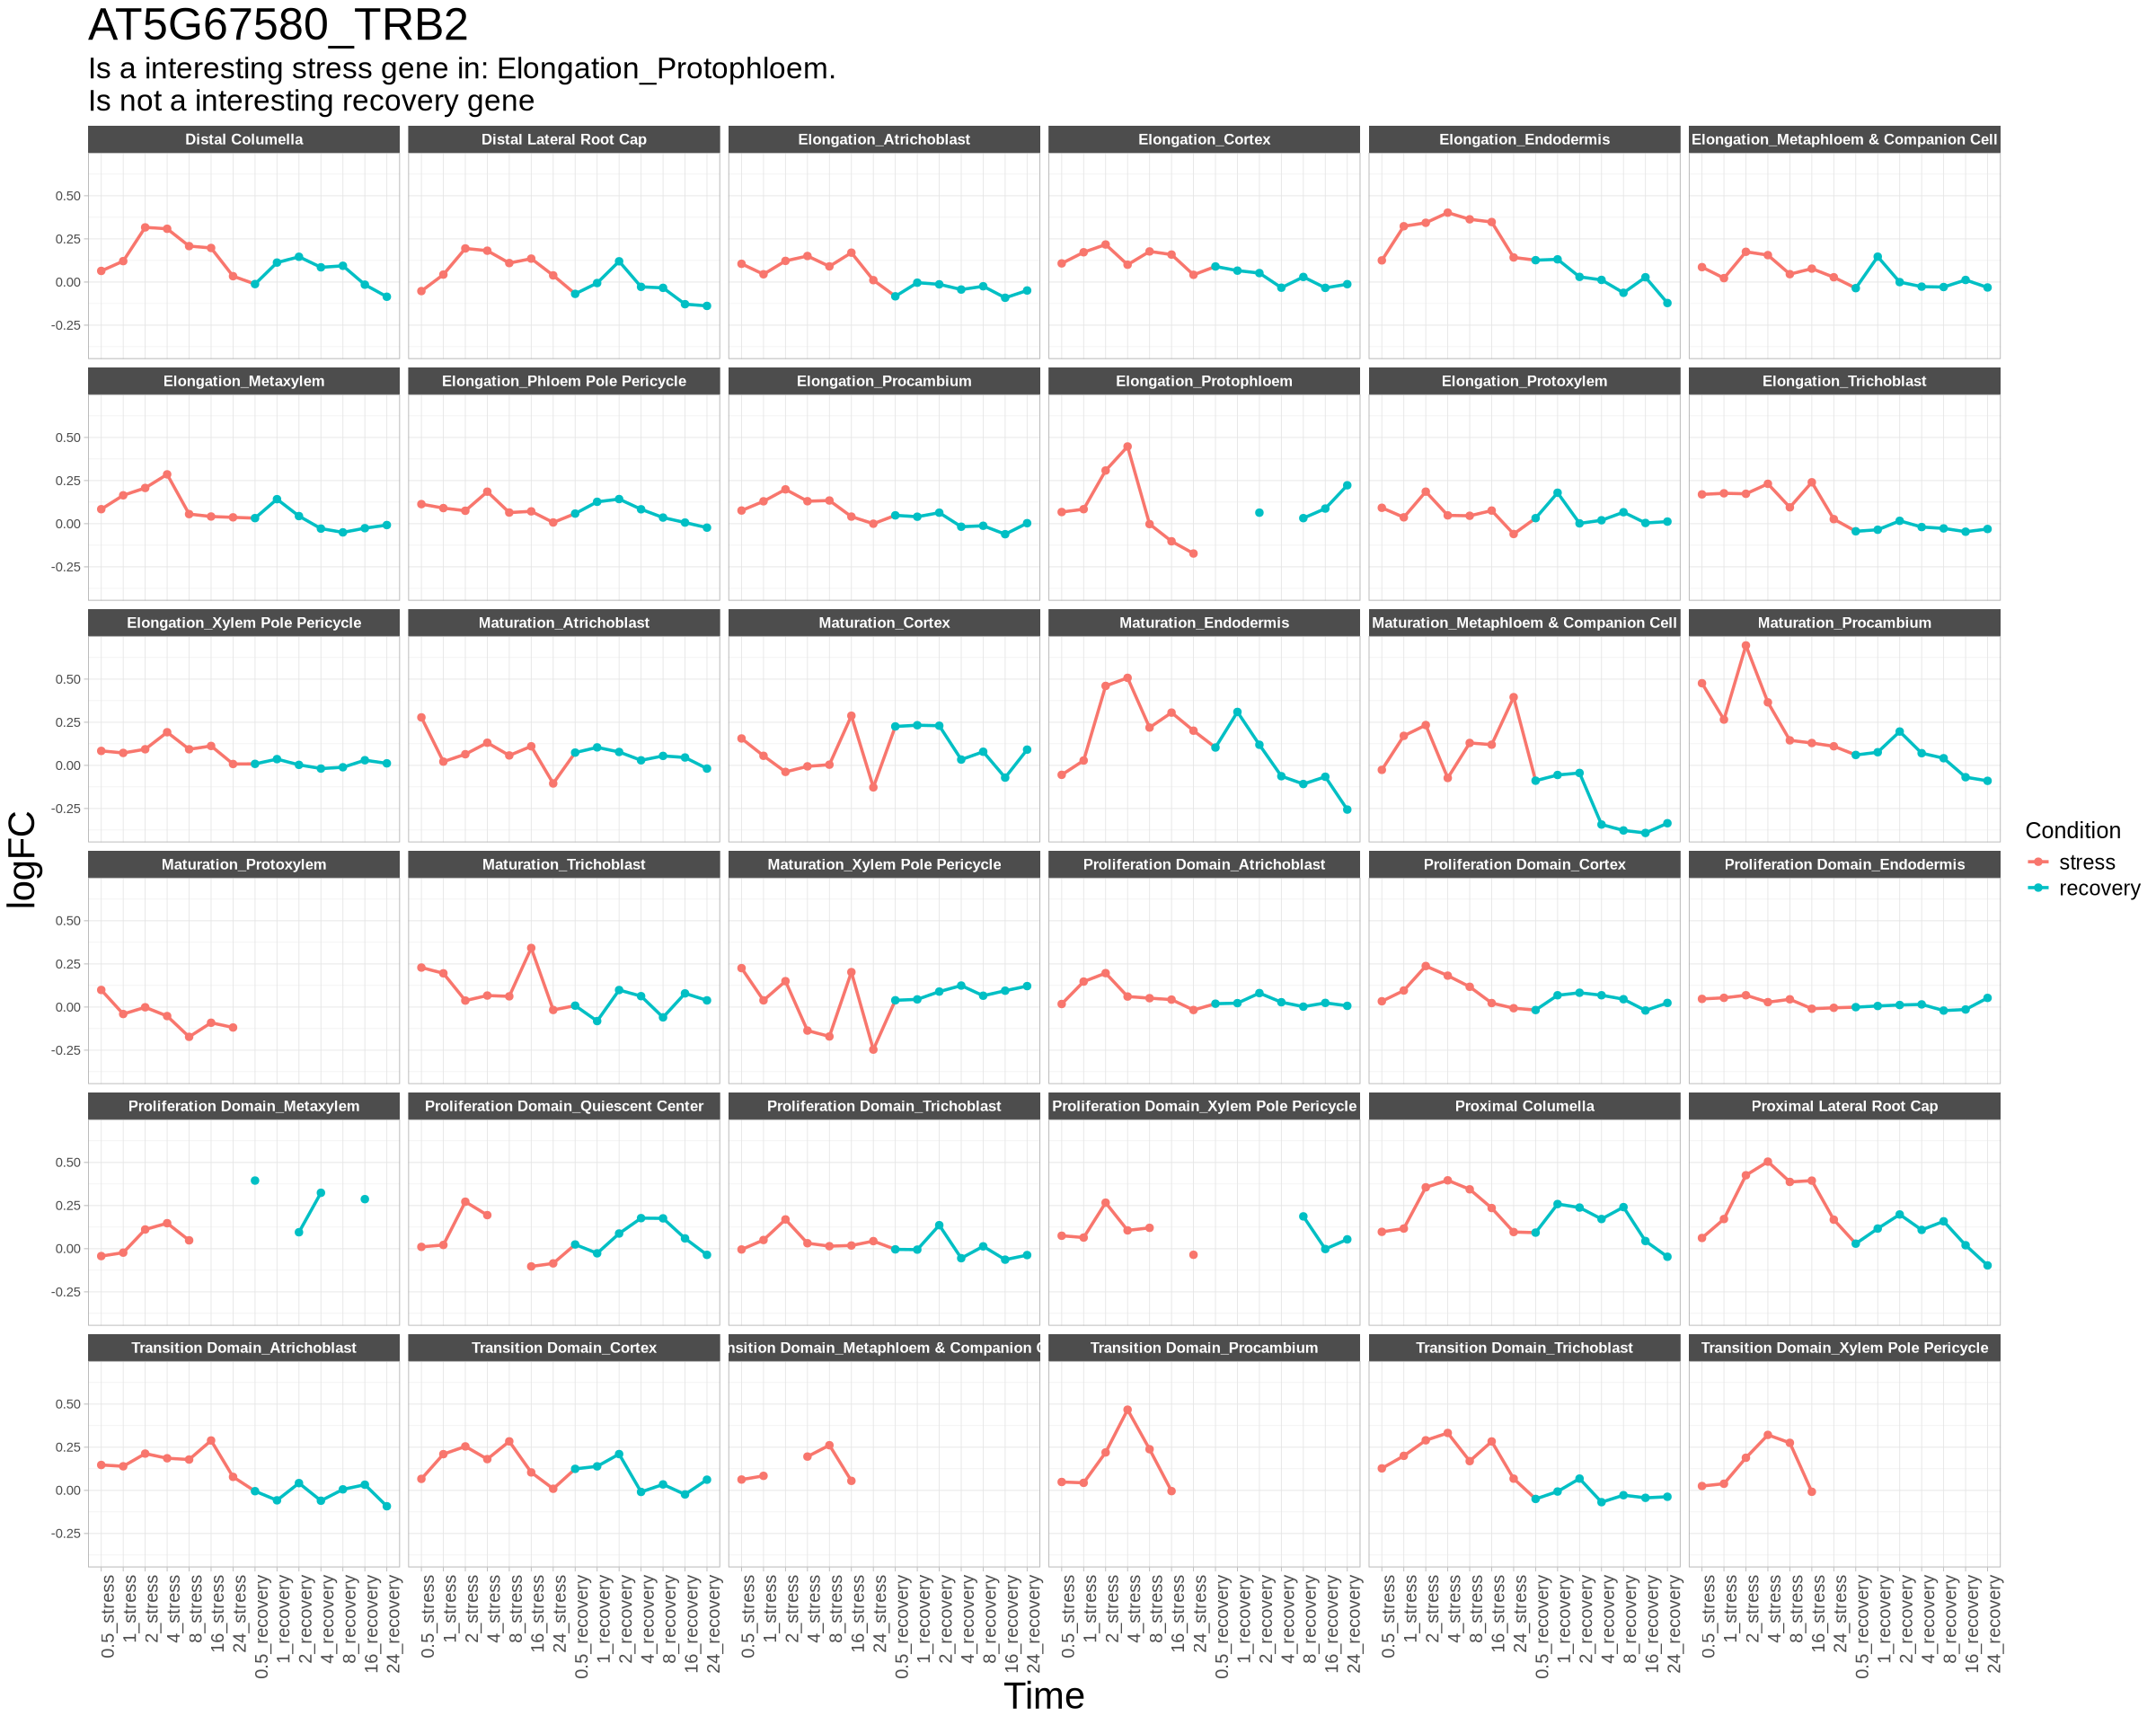

In [172]:
# Check a graph
options(repr.plot.width=20, repr.plot.height=16)
p

#### 

### Plot the number of genes in each category

In [120]:
combined_all_tbl_addLabel_TF_GE %>%
  filter(Label != "None") %>%
  group_by(Label, crude_cell_type) %>%
  count() %>%
  pivot_wider(names_from = crude_cell_type, values_from = n)

Label,atrichoblast,columella,cortex,endodermis,lrc,pericycle,phloem,procambium,trichoblast,xylem
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
WT_specific,34,56,83,1151,20,565,387,60,50,238
fer4_specific,125,113,131,509,71,720,515,151,149,362


In [121]:
summary <- combined_all_tbl_addLabel_TF_GE %>%
  filter(Label != "None") %>%
  group_by(crude_cell_type, cell_type, metric, Label, Is_TF) %>%
  count()

summary_wide <- summary %>%
  pivot_wider(values_from = n, names_from = metric) %>%
  mutate_at(vars(-group_cols()), ~ replace(., is.na(.), 0))  # Replace NA with 0, excluding grouping columns

head(summary)

crude_cell_type,cell_type,metric,Label,Is_TF,n
<chr>,<chr>,<chr>,<chr>,<chr>,<int>
atrichoblast,Elongation_Atrichoblast,betweenness_centrality,fer4_specific,Yes,22
atrichoblast,Elongation_Atrichoblast,degree_centrality_out,WT_specific,Yes,2
atrichoblast,Elongation_Atrichoblast,degree_centrality_out,fer4_specific,Yes,4
atrichoblast,Maturation_Atrichoblast,betweenness_centrality,WT_specific,Yes,2
atrichoblast,Maturation_Atrichoblast,betweenness_centrality,fer4_specific,Yes,26
atrichoblast,Maturation_Atrichoblast,degree_centrality_all,WT_specific,Yes,1


In [122]:
unique(summary$Label)

[1] "fer4_specific" "WT_specific"

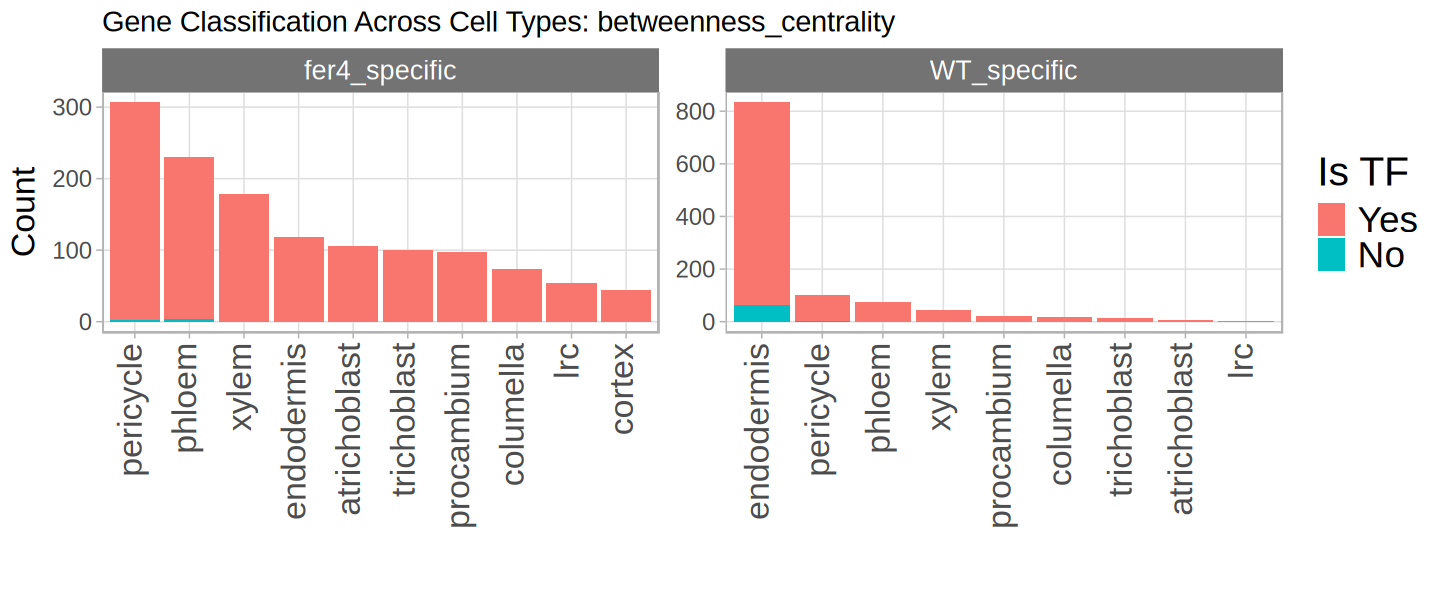

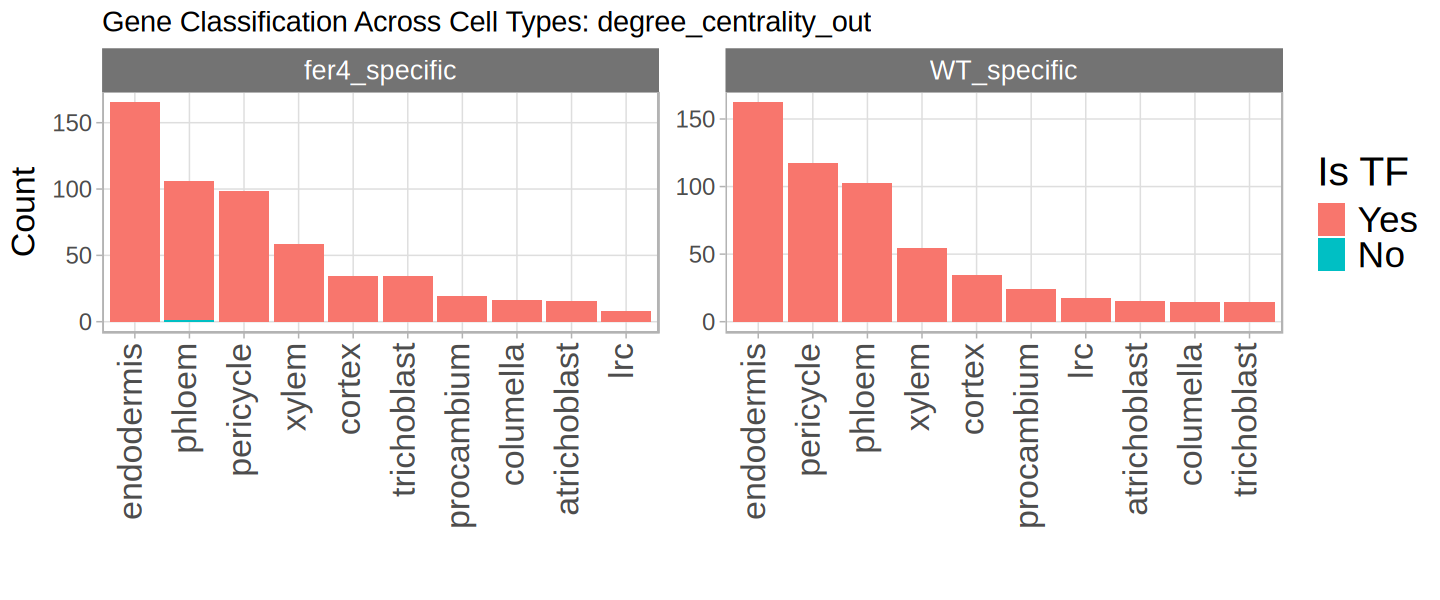

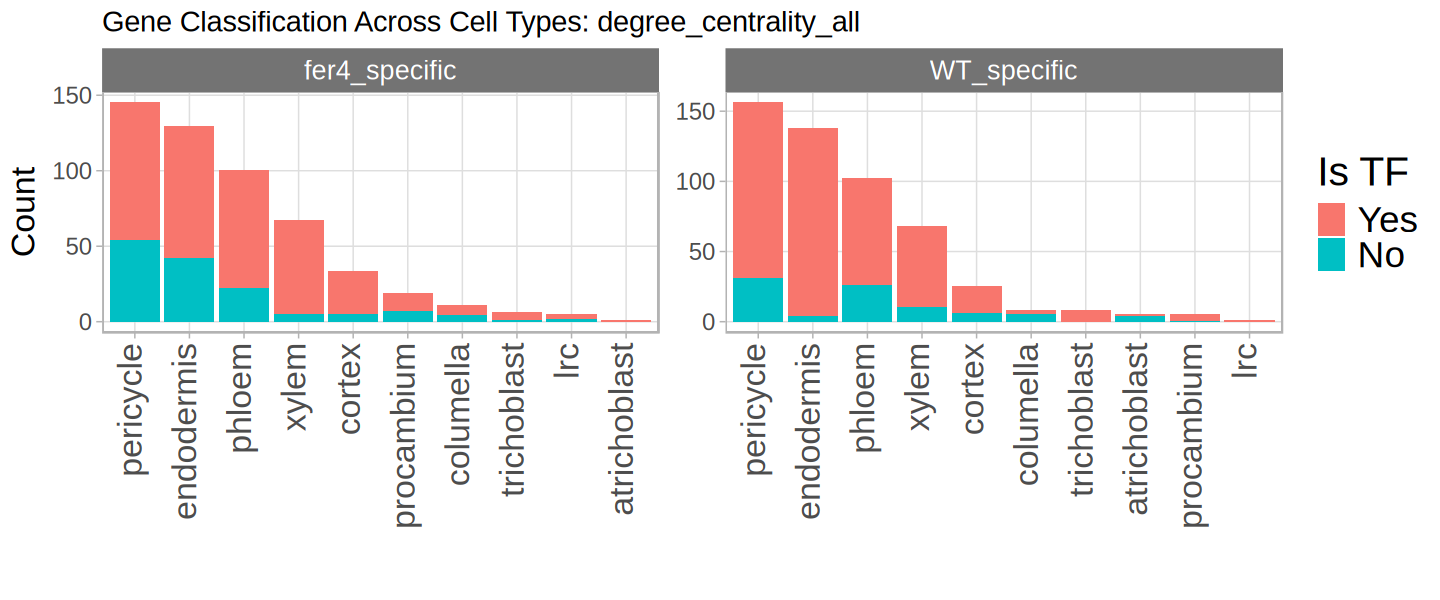

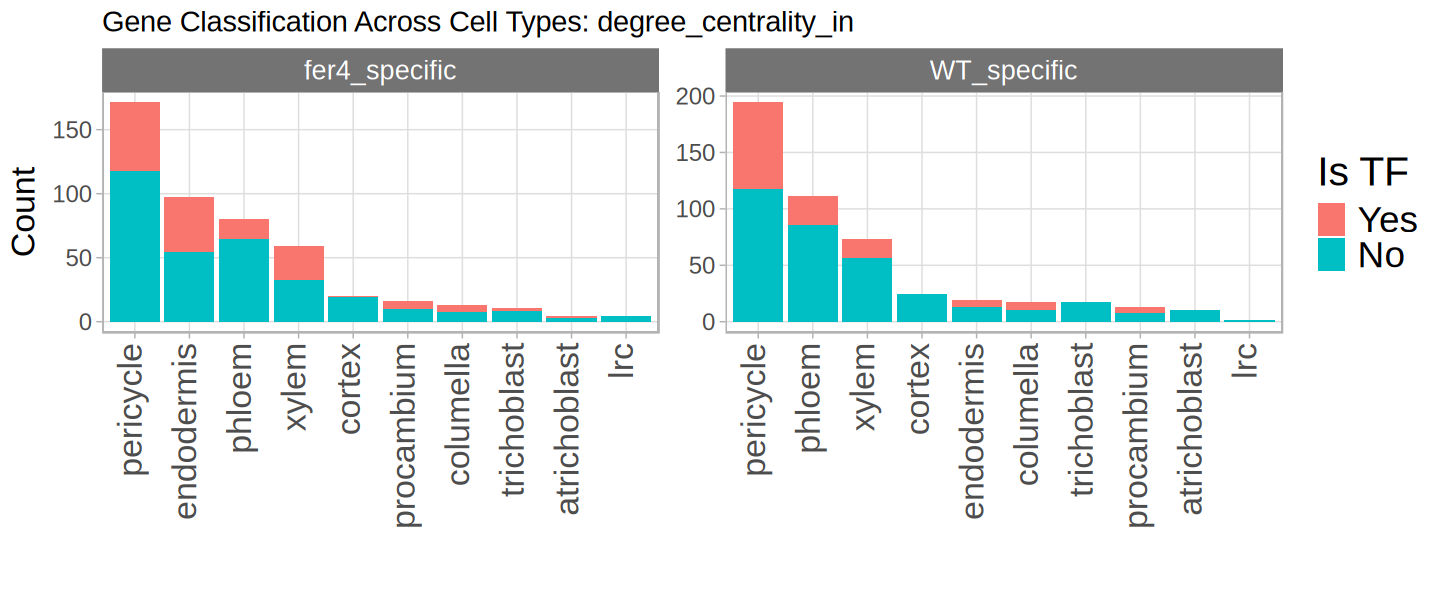

In [125]:
options(repr.plot.width = 12, repr.plot.height = 5)

summary$Is_TF <- factor(summary$Is_TF, levels = c("Yes", "No"))
summary$cell_type <- factor(summary$cell_type, levels = unique(summary$cell_type))

# Loop over each metric
for(m in unique(summary$metric)) {
  sub_data <- subset(summary, metric == m)
  
  # Reorder within each Label by the *sum* of n (rather than the mean)
  sub_data <- sub_data %>%
    group_by(Label, crude_cell_type) %>%
    mutate(total_n = sum(n)) %>% 
    ungroup() %>%
    mutate(crude_cell_type_reordered = tidytext::reorder_within(crude_cell_type, -total_n, Label, .fun = sum, ))
  
  p <- ggplot(sub_data, aes(x = crude_cell_type_reordered, y = n, fill = Is_TF)) +
    geom_bar(stat = "identity") +
    facet_wrap(. ~ Label, ncol = 2, scales = "free") +
    tidytext::scale_x_reordered() +
    theme_light(base_size = 14) +
    labs(x = "", y = "Count", fill = "Is TF", 
         title = paste("Gene Classification Across Cell Types:", m)) +
    theme(
      panel.grid.minor = element_blank(),
      axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3, size = 20),
      axis.text.y = element_text(size = 14),
      axis.title.x = element_text(size = 20),
      axis.title.y = element_text(size = 20),
      strip.text = element_text(size = 16),
      strip.background = element_rect(fill = "grey45"),
      legend.text = element_text(size = 22),
      legend.title = element_text(size = 24)
    )
  
  print(p)
}


In [124]:
unique(summary$metric)

[1] "betweenness_centrality" "degree_centrality_out"  "degree_centrality_all" 
[4] "degree_centrality_in"

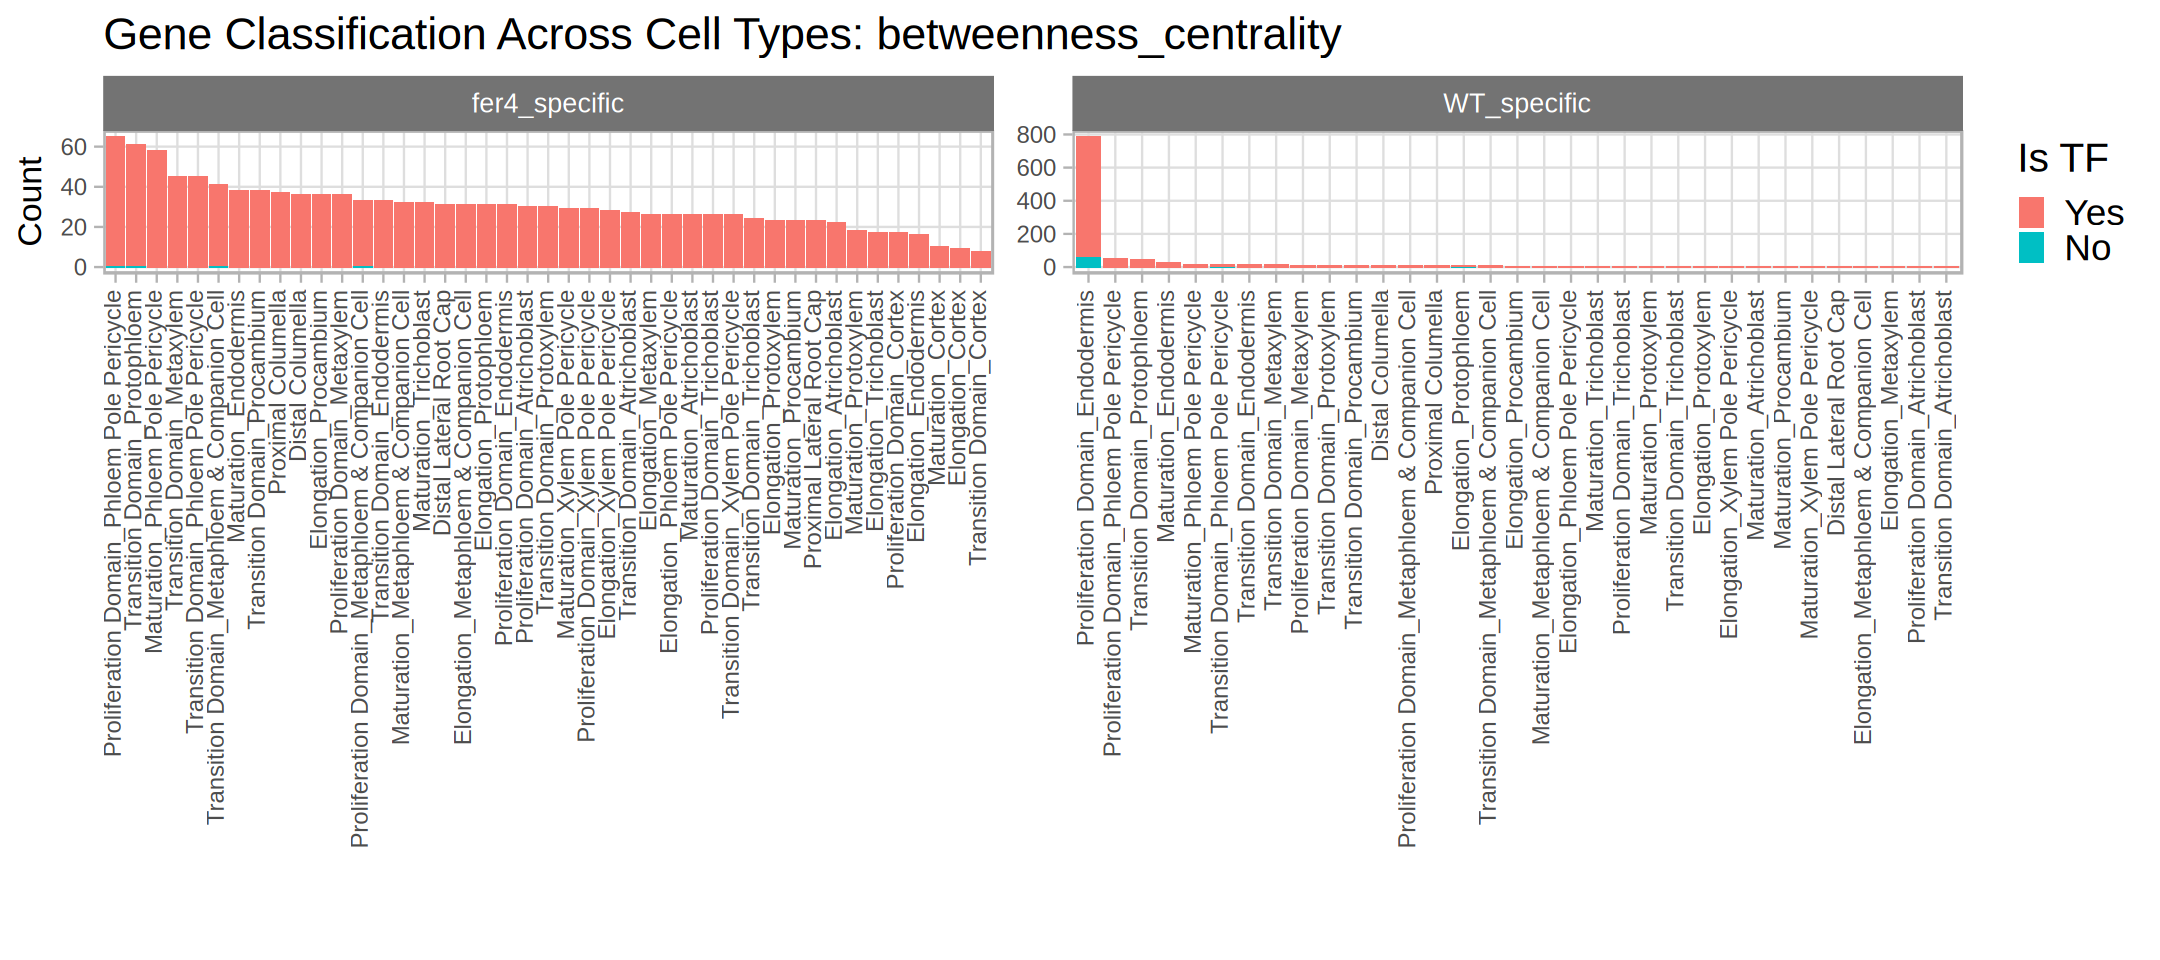

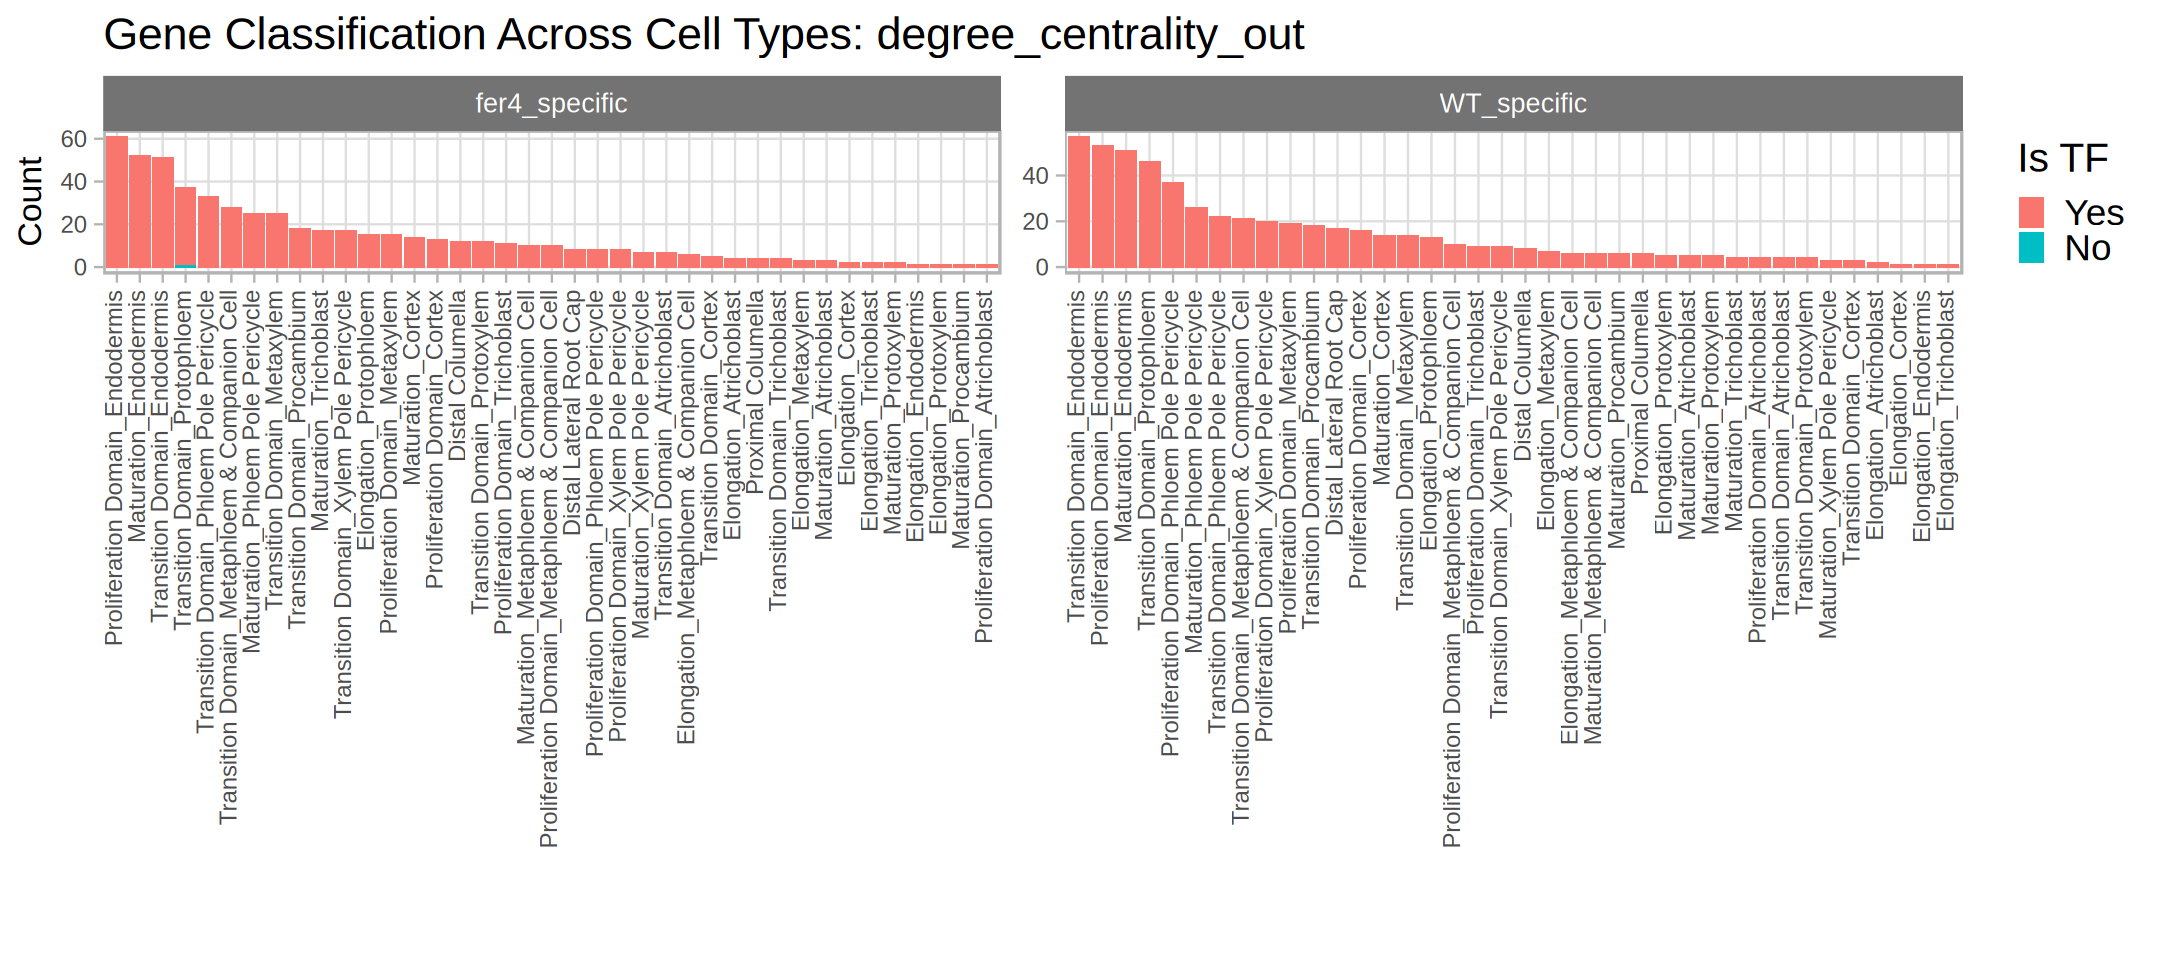

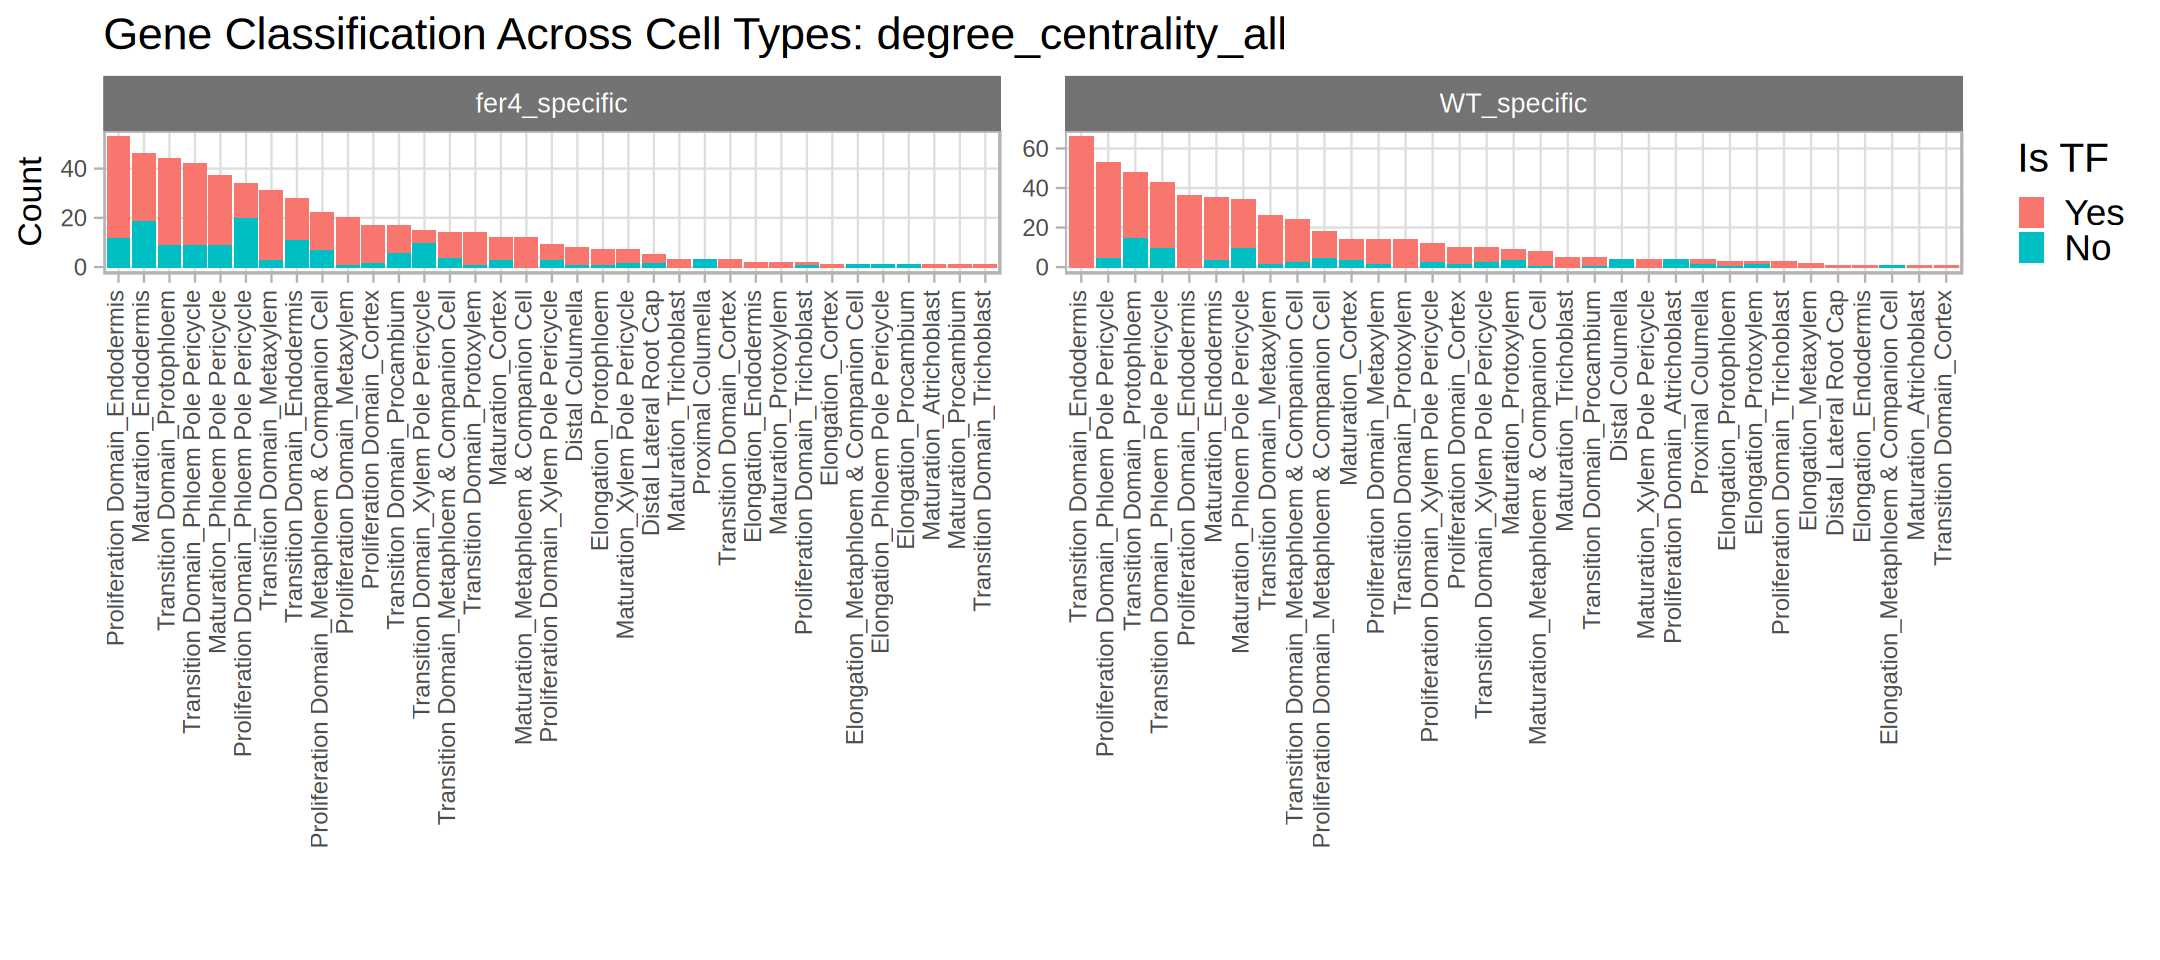

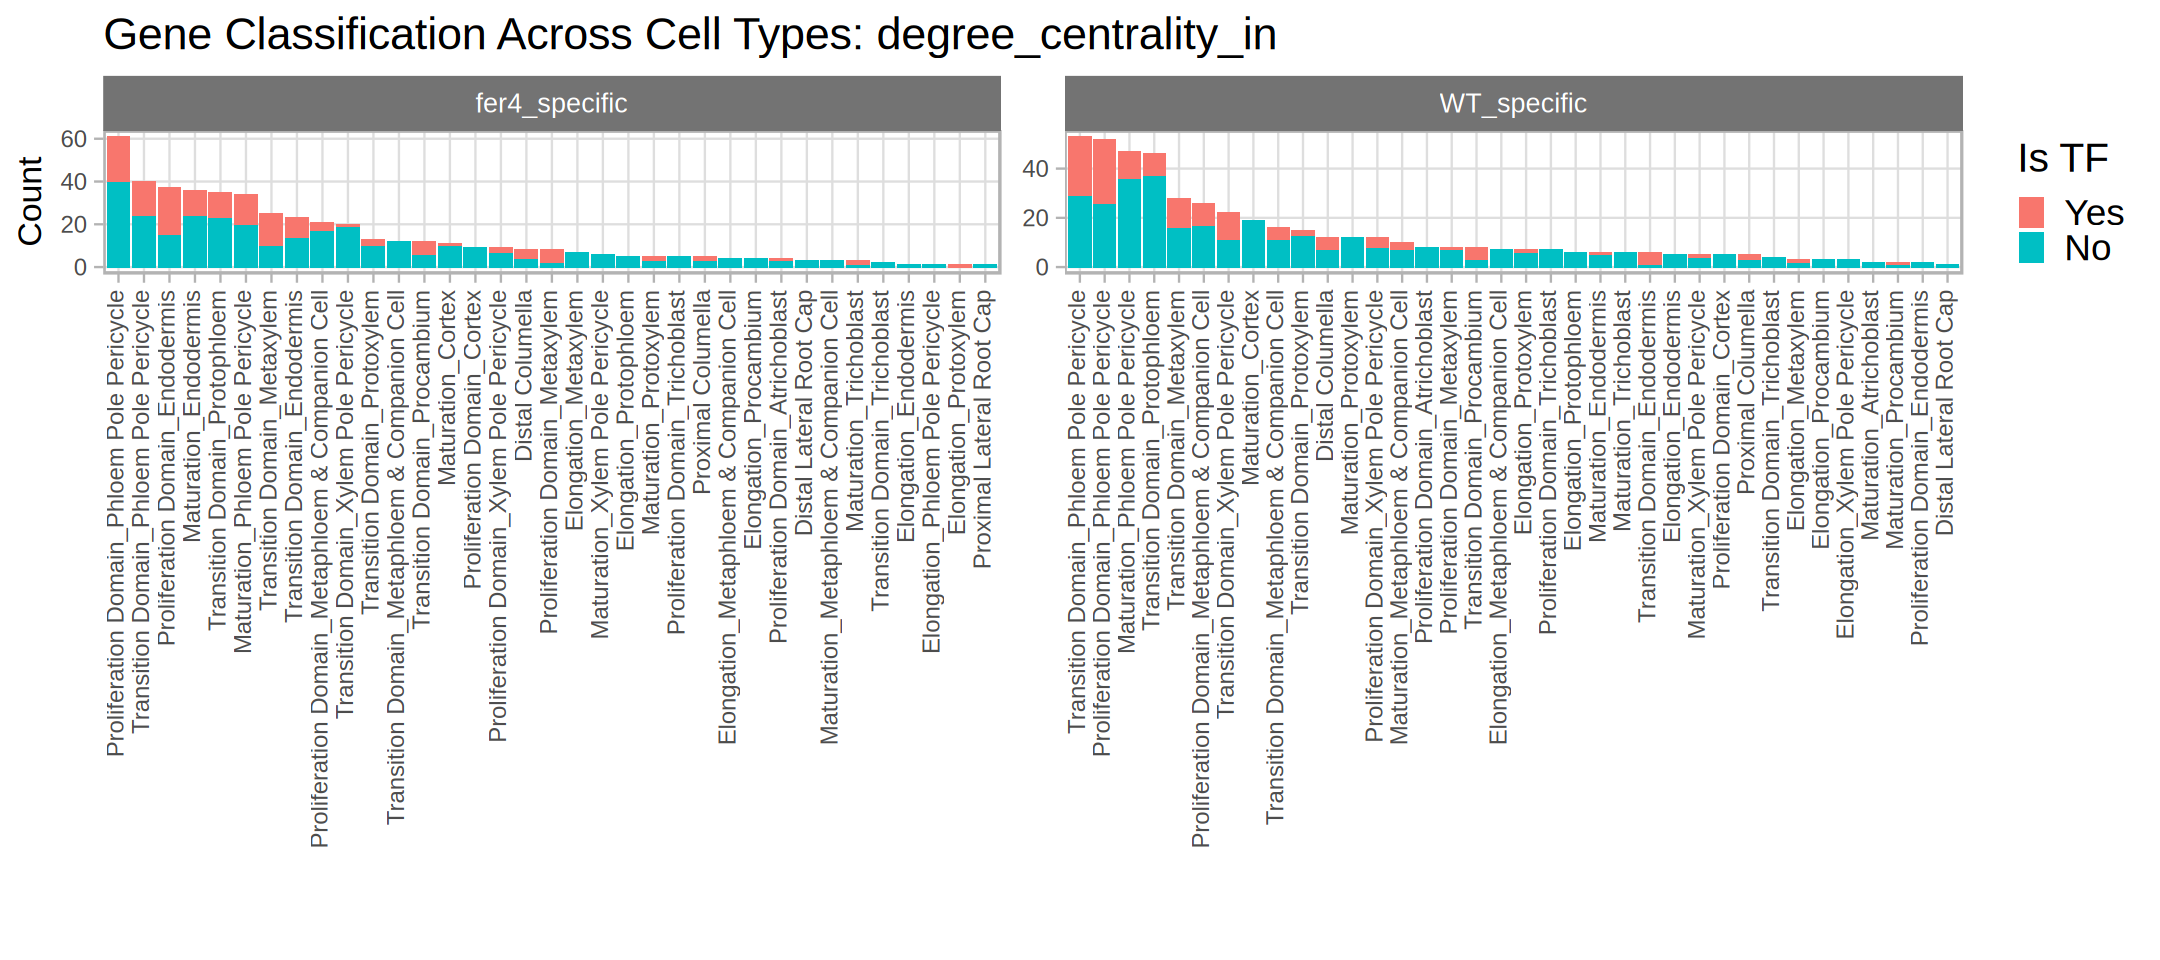

In [126]:
options(repr.plot.width = 18, repr.plot.height = 8)

summary$Is_TF <- factor(summary$Is_TF, levels = c("Yes", "No"))
summary$cell_type <- factor(summary$cell_type, levels = unique(summary$cell_type))

# Loop over each metric
for(m in unique(summary$metric)) {
  sub_data <- subset(summary, metric == m)
  
  # Reorder within each Label by the *sum* of n (rather than the mean)
  sub_data <- sub_data %>%
    group_by(Label, cell_type) %>%
    mutate(total_n = sum(n)) %>% 
    ungroup() %>%
    mutate(cell_type_reordered = tidytext::reorder_within(cell_type, -total_n, Label, .fun = sum, ))
  
  p <- ggplot(sub_data, aes(x = cell_type_reordered, y = n, fill = Is_TF)) +
    geom_bar(stat = "identity") +
    facet_wrap(. ~ Label, ncol = 3, scales = "free") +
    tidytext::scale_x_reordered() +
    theme_light(base_size = 22) +
    labs(x = "", y = "Count", fill = "Is TF", 
         title = paste("Gene Classification Across Cell Types:", m)) +
    theme(
      panel.grid.minor = element_blank(),
      axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3, size = 14),
      axis.text.y = element_text(size = 14),
      axis.title.x = element_text(size = 20),
      axis.title.y = element_text(size = 20),
      strip.text = element_text(size = 16),
      strip.background = element_rect(fill = "grey45"),
      legend.text = element_text(size = 22),
      legend.title = element_text(size = 24)
    )
  
  print(p)
}


## GO analysis on the predicted targets in CellOracle networks of each TF (NOT USED)


In [61]:
interesting_stress <- read.table("20250425_mannitol_fine_timepoints_celloracle_interesting_stress_enriched.txt", 
                                 sep = "\t", header = T)

In [62]:
interesting_recovery <- read.table("20250425_mannitol_fine_timepoints_celloracle_interesting_recovery_enriched.txt", 
                                 sep = "\t", header = T)

In [63]:
head(interesting_stress, 3)

,gene,name,crude_cell_type,cell_type,metric,stress_qvalue,recovery_qvalue,WT_0.5_man.WT_0..gene_rank_1,WT_0.5_man.WT_0..gene_rank_2,WT_0.5_man.WT_0..rank_diff,⋯,Marker_In_n_celltypes_WT_24_rec,CellOracle_label,CellOracle_lenient_label,Stable_ranking_count,Stress_enriched_count,Recovery_enriched_count,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<int>,⋯,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,AT4G29230,AT4G29230_anac075,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.893339e-06,4.135508e-04,205,702,-497,⋯,0,None,Stress_enriched,0,3,1,0,Yes,NAC075,NAC domain containing protein 75
2,AT1G18860,AT1G18860_WRKY61,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.459718e-44,5.986729e-27,200,565,-365,⋯,0,None,Stress_enriched,0,15,3,0,Yes,WRKY61,WRKY DNA-binding protein 61
3,AT1G18570,AT1G18570_MYB51,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.077698e-12,1.263298e-08,125,422,-297,⋯,0,None,Stress_enriched,0,4,0,0,Yes,MYB51,myb domain protein 51


In [180]:
"AT1G07640" %in% interesting_stress$gene

[1] TRUE

In [64]:
head(interesting_recovery, 3)

,gene,name,crude_cell_type,cell_type,metric,stress_qvalue,recovery_qvalue,WT_0.5_man.WT_0..gene_rank_1,WT_0.5_man.WT_0..gene_rank_2,WT_0.5_man.WT_0..rank_diff,⋯,Marker_In_n_celltypes_WT_24_rec,CellOracle_label,CellOracle_lenient_label,Stable_ranking_count,Stress_enriched_count,Recovery_enriched_count,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<int>,⋯,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,AT5G25810,AT5G25810_TINY,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,8.278341e-02,5.759627e-03,77,93,-16,⋯,0,None,Recovery_enriched,0,11,5,0,Yes,tny,Integrase-type DNA-binding superfamily protein
2,AT5G67450,AT5G67450_AZF1,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,8.564625e-06,1.316140e-04,541,313,228,⋯,0,None,Recovery_enriched,0,8,1,2,Yes,ZF1,zinc-finger protein 1
3,AT5G26660,AT5G26660_MYB86,atrichoblast,Maturation_Atrichoblast,degree_centrality_out,1.190337e-15,2.415963e-76,105,183,-78,⋯,0,None,Recovery_enriched,0,11,5,0,Yes,MYB86,myb domain protein 86


In [65]:
interesting_stress <- interesting_stress %>%
   mutate(category = "interesting_stress", .before = 1)

interesting_recovery <- interesting_recovery %>%
   mutate(category = "interesting_recovery", .before = 1)

In [66]:
interesting_all <- rbind(interesting_stress, interesting_recovery)

head(interesting_all, 3)

,category,gene,name,crude_cell_type,cell_type,metric,stress_qvalue,recovery_qvalue,WT_0.5_man.WT_0..gene_rank_1,WT_0.5_man.WT_0..gene_rank_2,⋯,Marker_In_n_celltypes_WT_24_rec,CellOracle_label,CellOracle_lenient_label,Stable_ranking_count,Stress_enriched_count,Recovery_enriched_count,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,⋯,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,interesting_stress,AT4G29230,AT4G29230_anac075,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.893339e-06,4.135508e-04,205,702,⋯,0,None,Stress_enriched,0,3,1,0,Yes,NAC075,NAC domain containing protein 75
2,interesting_stress,AT1G18860,AT1G18860_WRKY61,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.459718e-44,5.986729e-27,200,565,⋯,0,None,Stress_enriched,0,15,3,0,Yes,WRKY61,WRKY DNA-binding protein 61
3,interesting_stress,AT1G18570,AT1G18570_MYB51,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.077698e-12,1.263298e-08,125,422,⋯,0,None,Stress_enriched,0,4,0,0,Yes,MYB51,myb domain protein 51


In [67]:
getwd()

[1] "/resnick/groups/NolanLab/cchen/mannitol/Cell_oracle/CellOracle_outputs/20250425_mannitol_fine_timecourse_MAST_DE_1.5FC_Celloracle_slurmArray/analysis/tables/TF_gene"

In [68]:
# Read in network analysis results

# Get list of all matching CSV files in the directory
file_list <- list.files(path = "../../../", 
                        pattern = "_celloracle_network_iGRN.csv", 
                        full.names = TRUE, 
                        recursive = TRUE)

file_list

# Read and bind all files into a single data frame
network_res <- file_list %>%
  lapply(read.csv) %>%
  bind_rows()



[1] "../../..//atrichoblast_rawRNA_celloracle_network_iGRN.csv"
 [2] "../../..//columella_rawRNA_celloracle_network_iGRN.csv"   
 [3] "../../..//cortex_rawRNA_celloracle_network_iGRN.csv"      
 [4] "../../..//endodermis_rawRNA_celloracle_network_iGRN.csv"  
 [5] "../../..//lrc_rawRNA_celloracle_network_iGRN.csv"         
 [6] "../../..//pericycle_rawRNA_celloracle_network_iGRN.csv"   
 [7] "../../..//phloem_rawRNA_celloracle_network_iGRN.csv"      
 [8] "../../..//procambium_rawRNA_celloracle_network_iGRN.csv"  
 [9] "../../..//trichoblast_rawRNA_celloracle_network_iGRN.csv" 
[10] "../../..//xylem_rawRNA_celloracle_network_iGRN.csv"

In [194]:
"AT4G32730" %in% network_res$gene

[1] TRUE

In [187]:
network_res %>% filter(gene == "AT1G07640" & str_detect(cluster, pattern = "Elongation_Protophloem"))

gene,source_name,target,target_name,cluster,cell_type,coef_mean,coef_abs,p,X.logp
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
AT1G07640,OBP2,AT5G42980,TRX3,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.03037897,0.03037897,2.466548e-17,16.607910
AT1G07640,OBP2,AT5G42300,UBL5,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.02856606,0.02856606,2.520845e-13,12.598454
AT1G07640,OBP2,AT1G11185,AT1G11185,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.02792168,0.02792168,9.204978e-21,20.035977
AT1G07640,OBP2,AT4G37830,AT4G37830,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.02091616,0.02091616,1.281845e-11,10.892164
AT1G07640,OBP2,AT5G20010,RAN1,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.01971705,0.01971705,2.322506e-15,14.634043
AT1G07640,OBP2,AT5G12140,CYS1,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.01970462,0.01970462,3.541914e-16,15.450762
AT1G07640,OBP2,AT4G05050,UBQ11,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.01968392,0.01968392,1.486401e-14,13.827864
AT1G07640,OBP2,AT5G04080,AT5G04080,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.01959559,0.01959559,1.312983e-10,9.881741
AT1G07640,OBP2,AT5G16650,AT5G16650,Elongation_Protophloem_WT_0,Elongation_Protophloem,0.01870299,0.01870299,4.212067e-12,11.375505


In [69]:
head(network_res)

,X,source,source_name,target,target_name,cluster,coef_mean,coef_abs,p,X.logp
,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,445740,AT4G31800,WRKY18,AT2G07725,AT2G07725,Elongation_Atrichoblast_WT_0,0.6888100,0.6888100,5.938291e-15,14.226339
2,445737,AT3G50260,ERF011,AT2G07708,AT2G07708,Elongation_Atrichoblast_WT_0,0.6619415,0.6619415,4.708318e-16,15.327134
3,103795,AT5G65310,ATHB-5,AT1G15270,AT1G15270,Elongation_Atrichoblast_WT_0,0.4139011,0.4139011,1.353168e-15,14.868648
4,71436,AT2G40620,BZIP18,AT1G10630,ATARFA1F,Elongation_Atrichoblast_WT_0,0.4016980,0.4016980,1.562901e-16,15.806068
5,1113066,AT5G51780,AT5G51780,AT4G12510,AT4G12510,Elongation_Atrichoblast_WT_0,0.3475157,0.3475157,1.366290e-20,19.864457
6,445739,AT1G46264,HSFB4,AT2G07725,AT2G07725,Elongation_Atrichoblast_WT_0,0.3384347,0.3384347,8.346546e-08,7.078493


In [70]:
unique(network_res$cluster)[1:10]

[1] "Elongation_Atrichoblast_WT_0"       "Elongation_Atrichoblast_WT_0.5_man"
 [3] "Elongation_Atrichoblast_WT_0.5_rec" "Elongation_Atrichoblast_WT_16_man" 
 [5] "Elongation_Atrichoblast_WT_16_rec"  "Elongation_Atrichoblast_WT_1_man"  
 [7] "Elongation_Atrichoblast_WT_1_rec"   "Elongation_Atrichoblast_WT_24_man" 
 [9] "Elongation_Atrichoblast_WT_24_rec"  "Elongation_Atrichoblast_WT_2_man"

In [71]:
network_res <- network_res %>%
  mutate(cell_type = sub("_WT.*", "",  cluster), .after = cluster)

In [72]:
head(network_res, 3)


,X,source,source_name,target,target_name,cluster,cell_type,coef_mean,coef_abs,p,X.logp
,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,445740,AT4G31800,WRKY18,AT2G07725,AT2G07725,Elongation_Atrichoblast_WT_0,Elongation_Atrichoblast,0.6888100,0.6888100,5.938291e-15,14.22634
2,445737,AT3G50260,ERF011,AT2G07708,AT2G07708,Elongation_Atrichoblast_WT_0,Elongation_Atrichoblast,0.6619415,0.6619415,4.708318e-16,15.32713
3,103795,AT5G65310,ATHB-5,AT1G15270,AT1G15270,Elongation_Atrichoblast_WT_0,Elongation_Atrichoblast,0.4139011,0.4139011,1.353168e-15,14.86865


In [73]:
network_res$X <- NULL

In [74]:
colnames(network_res)[1] <- "gene"

In [75]:
head(network_res, 3)

,gene,source_name,target,target_name,cluster,cell_type,coef_mean,coef_abs,p,X.logp
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,AT4G31800,WRKY18,AT2G07725,AT2G07725,Elongation_Atrichoblast_WT_0,Elongation_Atrichoblast,0.6888100,0.6888100,5.938291e-15,14.22634
2,AT3G50260,ERF011,AT2G07708,AT2G07708,Elongation_Atrichoblast_WT_0,Elongation_Atrichoblast,0.6619415,0.6619415,4.708318e-16,15.32713
3,AT5G65310,ATHB-5,AT1G15270,AT1G15270,Elongation_Atrichoblast_WT_0,Elongation_Atrichoblast,0.4139011,0.4139011,1.353168e-15,14.86865


In [76]:
min(network_res$coef_abs)
max(network_res$coef_abs)

round(quantile(network_res$coef_abs, probs = seq(0, 1, 0.25)), 3)

[1] 0.0002815607

[1] 2.521368

0%   25%   50%   75%  100% 
0.000 0.015 0.028 0.042 2.521

In [77]:
min(network_res$p)
max(network_res$p)

[1] 2.438233e-30

[1] 0.009999489

In [78]:
head(interesting_all, 3)

,category,gene,name,crude_cell_type,cell_type,metric,stress_qvalue,recovery_qvalue,WT_0.5_man.WT_0..gene_rank_1,WT_0.5_man.WT_0..gene_rank_2,⋯,Marker_In_n_celltypes_WT_24_rec,CellOracle_label,CellOracle_lenient_label,Stable_ranking_count,Stress_enriched_count,Recovery_enriched_count,NA_group_count,Is_TF,TF_name,TF_description
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,⋯,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,interesting_stress,AT4G29230,AT4G29230_anac075,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.893339e-06,4.135508e-04,205,702,⋯,0,None,Stress_enriched,0,3,1,0,Yes,NAC075,NAC domain containing protein 75
2,interesting_stress,AT1G18860,AT1G18860_WRKY61,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.459718e-44,5.986729e-27,200,565,⋯,0,None,Stress_enriched,0,15,3,0,Yes,WRKY61,WRKY DNA-binding protein 61
3,interesting_stress,AT1G18570,AT1G18570_MYB51,atrichoblast,Elongation_Atrichoblast,degree_centrality_out,2.077698e-12,1.263298e-08,125,422,⋯,0,None,Stress_enriched,0,4,0,0,Yes,MYB51,myb domain protein 51


In [79]:
interesting_all_sub <- interesting_all %>%
   dplyr::select(1, 2, 3, 128, 129, 4, 5)

head(interesting_all_sub, 3)

,category,gene,name,TF_name,TF_description,crude_cell_type,cell_type
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast
2,interesting_stress,AT1G18860,AT1G18860_WRKY61,WRKY61,WRKY DNA-binding protein 61,atrichoblast,Elongation_Atrichoblast
3,interesting_stress,AT1G18570,AT1G18570_MYB51,MYB51,myb domain protein 51,atrichoblast,Elongation_Atrichoblast


In [80]:
n_distinct(interesting_all_sub$gene)

[1] 373

In [81]:
network_res_interesting <- left_join(interesting_all_sub, network_res, 
                                     by = c("gene", "cell_type"))

In [82]:
head(network_res_interesting)
nrow(network_res_interesting)
n_distinct(network_res_interesting$gene)

,category,gene,name,TF_name,TF_description,crude_cell_type,cell_type,source_name,target,target_name,cluster,coef_mean,coef_abs,p,X.logp
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G09140,SR30,Elongation_Atrichoblast_WT_0,0.03443887,0.03443887,6.941842e-08,7.158525
2,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G09140,SR30,Elongation_Atrichoblast_WT_0.5_man,0.13237396,0.13237396,1.269289e-08,7.896439
3,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT3G03070,AT3G03070,Elongation_Atrichoblast_WT_0.5_man,-0.07865059,0.07865059,3.153225e-12,11.501245
4,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT3G56310,AGAL3,Elongation_Atrichoblast_WT_0.5_man,0.07082030,0.07082030,3.872890e-11,10.411965
5,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT2G02050,AT2G02050,Elongation_Atrichoblast_WT_0.5_man,-0.06186344,0.06186344,4.574039e-14,13.339700
6,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G65310,ATXTH17,Elongation_Atrichoblast_WT_0.5_man,-0.05921045,0.05921045,6.457832e-11,10.189913


[1] 856171

[1] 373

In [83]:
min(network_res_interesting$coef_abs)
max(network_res_interesting$coef_abs)

round(quantile(network_res_interesting$coef_abs, probs = seq(0, 1, 0.25)), 3)

[1] 0.0007158133

[1] 0.6310967

0%   25%   50%   75%  100% 
0.001 0.022 0.033 0.047 0.631

In [84]:
network_res_interesting %>% group_by(gene, cell_type) %>%
   count()

gene,cell_type,n
<chr>,<chr>,<int>
AT1G03800,Proliferation Domain_Cortex,96
AT1G03840,Elongation_Cortex,63
AT1G03840,Maturation_Cortex,42
AT1G03840,Proliferation Domain_Cortex,745
AT1G03840,Transition Domain_Cortex,446
AT1G06070,Distal Lateral Root Cap,738
AT1G06180,Proliferation Domain_Cortex,902
AT1G06850,Transition Domain_Cortex,217
AT1G07640,Distal Columella,176


In [193]:
network_res_interesting %>% filter(gene == "AT1G07640" & cell_type == "Elongation_Protophloem")

category,gene,name,TF_name,TF_description,crude_cell_type,cell_type,source_name,target,target_name,cluster,coef_mean,coef_abs,p,X.logp
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT5G42980,TRX3,Elongation_Protophloem_WT_0,0.03037897,0.03037897,2.466548e-17,16.607910
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT5G42300,UBL5,Elongation_Protophloem_WT_0,0.02856606,0.02856606,2.520845e-13,12.598454
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT1G11185,AT1G11185,Elongation_Protophloem_WT_0,0.02792168,0.02792168,9.204978e-21,20.035977
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT4G37830,AT4G37830,Elongation_Protophloem_WT_0,0.02091616,0.02091616,1.281845e-11,10.892164
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT5G20010,RAN1,Elongation_Protophloem_WT_0,0.01971705,0.01971705,2.322506e-15,14.634043
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT5G12140,CYS1,Elongation_Protophloem_WT_0,0.01970462,0.01970462,3.541914e-16,15.450762
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT4G05050,UBQ11,Elongation_Protophloem_WT_0,0.01968392,0.01968392,1.486401e-14,13.827864
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT5G04080,AT5G04080,Elongation_Protophloem_WT_0,0.01959559,0.01959559,1.312983e-10,9.881741
interesting_stress,AT1G07640,AT1G07640_OBP2,OBP2,Dof-type zinc finger DNA-binding family protein,phloem,Elongation_Protophloem,OBP2,AT5G16650,AT5G16650,Elongation_Protophloem_WT_0,0.01870299,0.01870299,4.212067e-12,11.375505


In [85]:
# Filter based on coef_abs (50%)
coef_abs_cutoff <- quantile(network_res_interesting$coef_abs, probs = 0.5)

network_res_interesting_sub <- network_res_interesting %>%
  filter(coef_abs >= coef_abs_cutoff)

nrow(network_res_interesting_sub)

[1] 428086

In [86]:
network_res_interesting_sub %>% group_by(gene, cell_type) %>%
   count() %>% arrange(desc(n))

gene,cell_type,n
<chr>,<chr>,<int>
AT2G45050,Transition Domain_Cortex,5149
AT5G15150,Transition Domain_Cortex,4765
AT5G15150,Elongation_Cortex,4602
AT3G10800,Elongation_Cortex,4041
AT3G01220,Elongation_Cortex,3883
AT3G01220,Transition Domain_Cortex,3412
AT1G49480,Transition Domain_Cortex,3209
AT3G60530,Transition Domain_Cortex,3022
AT5G11260,Transition Domain_Cortex,2817


In [192]:
network_res_interesting_sub %>% filter(gene == "AT1G07640" & cell_type == "Elongation_Protophloem")

category,gene,name,TF_name,TF_description,crude_cell_type,cell_type,source_name,target,target_name,cluster,coef_mean,coef_dir,coef_abs,p,X.logp
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>


In [87]:
network_res_interesting_sub <- network_res_interesting_sub %>%
   mutate(coef_dir = ifelse(coef_mean > 0, yes = "positive", no = "negative"), .after = coef_mean)

In [88]:
head(network_res_interesting_sub, 3)

,category,gene,name,TF_name,TF_description,crude_cell_type,cell_type,source_name,target,target_name,cluster,coef_mean,coef_dir,coef_abs,p,X.logp
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G09140,SR30,Elongation_Atrichoblast_WT_0,0.03443887,positive,0.03443887,6.941842e-08,7.158525
2,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G09140,SR30,Elongation_Atrichoblast_WT_0.5_man,0.13237396,positive,0.13237396,1.269289e-08,7.896439
3,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT3G03070,AT3G03070,Elongation_Atrichoblast_WT_0.5_man,-0.07865059,negative,0.07865059,3.153225e-12,11.501245


In [89]:
network_res_interesting_sub %>% group_by(gene, cell_type, coef_dir) %>%
   count() %>% arrange(desc(n))

gene,cell_type,coef_dir,n
<chr>,<chr>,<chr>,<int>
AT5G15150,Transition Domain_Cortex,positive,4765
AT2G45050,Transition Domain_Cortex,positive,4681
AT3G10800,Elongation_Cortex,positive,3932
AT5G15150,Elongation_Cortex,positive,3919
AT3G01220,Elongation_Cortex,positive,3438
AT3G01220,Transition Domain_Cortex,positive,3412
AT1G49480,Transition Domain_Cortex,positive,3206
AT5G11260,Transition Domain_Cortex,positive,2817
AT2G45050,Proliferation Domain_Cortex,positive,2718


In [90]:
# Read in DE and TF gene table used for CellOracle as GO background
DE_tbl <- read.csv("/resnick/groups/NolanLab/cchen/mannitol/analysis/20250310_mannitol_MAST_FC1.5_DE_sig_unique_per_cluster.csv", 
                   header = T)

wanted_TFs = read.csv("/resnick/groups/NolanLab/shared_resources/source_files/celloracle_inputs/Kay_TF_thalemine_annotations.csv",
                     header = T)

In [91]:
head(DE_tbl, 3)

,cluster_id,gene
,<chr>,<chr>
1,Elongation_Endodermis,AT1G01050
2,Elongation_Endodermis,AT1G01100
3,Elongation_Endodermis,AT1G01230


In [92]:
head(wanted_TFs)

,GeneID,Name,Description
,<chr>,<chr>,<chr>
1,AT1G01010,NAC001,NAC domain containing protein 1
2,AT1G01030,NGA3,AP2/B3-like transcriptional factor family protein
3,AT1G01060,LHY,Homeodomain-like superfamily protein
4,AT1G01250,AT1G01250,Integrase-type DNA-binding superfamily protein
5,AT1G01260,AT1G01260,basic helix-loop-helix (bHLH) DNA-binding superfamily protein
6,AT1G01380,ETC1,Homeodomain-like superfamily protein


In [93]:
my_bg_genes <- unique(c(DE_tbl$gene, wanted_TFs$GeneID))
length(my_bg_genes)

[1] 8677

In [94]:
head(network_res_interesting_sub, 2)

,category,gene,name,TF_name,TF_description,crude_cell_type,cell_type,source_name,target,target_name,cluster,coef_mean,coef_dir,coef_abs,p,X.logp
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G09140,SR30,Elongation_Atrichoblast_WT_0,0.03443887,positive,0.03443887,6.941842e-08,7.158525
2,interesting_stress,AT4G29230,AT4G29230_anac075,NAC075,NAC domain containing protein 75,atrichoblast,Elongation_Atrichoblast,anac075,AT1G09140,SR30,Elongation_Atrichoblast_WT_0.5_man,0.13237396,positive,0.13237396,1.269289e-08,7.896439


In [95]:
network_res_interesting_sub %>% group_by(gene) %>% summarise(cell_type = n_distinct(cell_type))

gene,cell_type
<chr>,<int>
AT1G03800,1
AT1G03840,4
AT1G06070,1
AT1G06180,1
AT1G06850,1
AT1G07640,5
AT1G08010,5
AT1G08810,2
AT1G09530,4


In [96]:
# Get unique TF–cell_type–direction combinations
tf_combos <- network_res_interesting_sub %>%
  distinct(gene, cell_type, coef_dir)

tf_combos %>% arrange(gene)

nrow(tf_combos)

gene,cell_type,coef_dir
<chr>,<chr>,<chr>
AT1G03800,Proliferation Domain_Cortex,positive
AT1G03800,Proliferation Domain_Cortex,negative
AT1G03840,Elongation_Cortex,negative
AT1G03840,Elongation_Cortex,positive
AT1G03840,Maturation_Cortex,negative
AT1G03840,Maturation_Cortex,positive
AT1G03840,Transition Domain_Cortex,positive
AT1G03840,Transition Domain_Cortex,negative
AT1G03840,Proliferation Domain_Cortex,positive


[1] 2015

In [190]:
tf_combos %>% filter(gene == "AT1G07640")

gene,cell_type,coef_dir
<chr>,<chr>,<chr>
AT1G07640,Proliferation Domain_Atrichoblast,positive
AT1G07640,Proliferation Domain_Atrichoblast,negative
AT1G07640,Proliferation Domain_Cortex,positive
AT1G07640,Proliferation Domain_Cortex,negative
AT1G07640,Elongation_Xylem Pole Pericycle,negative
AT1G07640,Elongation_Xylem Pole Pericycle,positive
AT1G07640,Maturation_Metaphloem & Companion Cell,positive
AT1G07640,Distal Columella,positive
AT1G07640,Distal Columella,negative


In [97]:
# Initialize list to collect GO results
go_results_list <- list()

# Loop over each combination
for (i in 1:nrow(tf_combos)) {
#for (i in 1:3) {
  tf <- tf_combos$gene[i]
  celltype_name <- tf_combos$cell_type[i]
  direction <- tf_combos$coef_dir[i]
  
  cat("Processing TF:", tf, "| Cell type:", celltype_name, "| Direction:", direction, "\n")
  
  # Get target genes regulated by this TF in this cell type and direction
  target_genes <- network_res_interesting_sub %>%
    filter(gene == tf, cell_type == celltype_name, coef_dir == direction) %>%
    pull(target) %>%
    unique()
  
  # Skip if too few genes
  if (length(target_genes) < 5) {
    cat("Too few target genes (", length(target_genes), ") - skipping\n")
    next
  }
  
  # Run GO analysis
  gostres <- gost(
    query = target_genes, 
    organism = "athaliana", 
    ordered_query = FALSE, 
    multi_query = FALSE, 
    significant = TRUE, 
    exclude_iea = FALSE, 
    measure_underrepresentation = FALSE,
    evcodes = TRUE,
    user_threshold = 0.05, 
    correction_method = "fdr", 
    domain_scope = "custom_annotated",
    custom_bg = my_bg_genes,
    numeric_ns = "",
    sources = NULL,
    as_short_link = FALSE,
    highlight = TRUE
  )

  
  if (is.null(gostres$result)) {
    cat("No significant GO terms found - skipping\n")
    next
  }
  
  # Annotate the result with the TF, cell type, and direction
  gostres$result$TF <- tf
  gostres$result$cell_type <- celltype_name
  gostres$result$coef_dir <- direction
  
  # Store in list
  list_name <- paste(tf, celltype_name, direction, sep = "_")
  go_results_list[[list_name]] <- gostres$result
}

# Combine all results
all_go_results <- bind_rows(go_results_list)

# Flatten list columns
all_go_results <- all_go_results %>%
  mutate(
    parents = sapply(parents, paste, collapse = ","),
    intersection = sapply(intersection, paste, collapse = ",")
  ) %>%
  dplyr::select(TF, cell_type, coef_dir, everything())

# Save
 #write.table(all_go_results, 
 #            "20250425_mannitol_fine_timepoints_celloracle_interesting_TF_GO_analysis.txt", 
 #            sep = "\t", row.names = FALSE, quote = FALSE)


Processing TF: AT4G29230 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT4G29230 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT1G18860 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT1G18860 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT1G18570 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT1G18570 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT5G61590 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT5G61590 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT4G26930 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT4G26930 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT1G51140 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT1G51140 | Cell type: Elongation_Atrichoblast | D

No results to show
Please make sure that the organism is correct or set significant = FALSE



No significant GO terms found - skipping
Processing TF: AT2G40750 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT2G40750 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT4G38620 | Cell type: Elongation_Atrichoblast | Direction: negative 
Processing TF: AT4G38620 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT1G19350 | Cell type: Elongation_Atrichoblast | Direction: positive 
Too few target genes ( 3 ) - skipping
Processing TF: AT1G19350 | Cell type: Elongation_Atrichoblast | Direction: negative 
Too few target genes ( 2 ) - skipping
Processing TF: AT3G57800 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT3G57800 | Cell type: Elongation_Atrichoblast | Direction: negative 
Too few target genes ( 1 ) - skipping
Processing TF: AT5G15130 | Cell type: Elongation_Atrichoblast | Direction: positive 
Processing TF: AT5G15130 | Cell type: Elongation_Atrichoblast | Direction: negat

No results to show
Please make sure that the organism is correct or set significant = FALSE



No significant GO terms found - skipping
Processing TF: AT5G48560 | Cell type: Maturation_Atrichoblast | Direction: positive 
Processing TF: AT5G48560 | Cell type: Maturation_Atrichoblast | Direction: negative 


...

No significant GO terms found - skipping
Processing TF: AT3G60530 | Cell type: Elongation_Procambium | Direction: positive 
Processing TF: AT2G46680 | Cell type: Elongation_Procambium | Direction: positive 


No results to show
Please make sure that the organism is correct or set significant = FALSE



No significant GO terms found - skipping
Processing TF: AT2G46680 | Cell type: Elongation_Procambium | Direction: negative 
Processing TF: AT2G28810 | Cell type: Elongation_Procambium | Direction: negative 
Processing TF: AT2G28810 | Cell type: Elongation_Procambium | Direction: positive 
Processing TF: AT2G37590 | Cell type: Elongation_Procambium | Direction: positive 
Processing TF: AT2G37590 | Cell type: Elongation_Procambium | Direction: negative 
Processing TF: AT5G08130 | Cell type: Elongation_Procambium | Direction: negative 
Processing TF: AT5G08130 | Cell type: Elongation_Procambium | Direction: positive 
Processing TF: AT5G13080 | Cell type: Elongation_Procambium | Direction: negative 
Processing TF: AT5G13080 | Cell type: Elongation_Procambium | Direction: positive 
Processing TF: AT4G17460 | Cell type: Elongation_Procambium | Direction: positive 
Processing TF: AT4G17460 | Cell type: Elongation_Procambium | Direction: negative 
Processing TF: AT4G37940 | Cell type: Elongati

No results to show
Please make sure that the organism is correct or set significant = FALSE



No significant GO terms found - skipping
Processing TF: AT2G46680 | Cell type: Maturation_Procambium | Direction: negative 
Too few target genes ( 2 ) - skipping
Processing TF: AT5G08520 | Cell type: Elongation_Trichoblast | Direction: positive 
Processing TF: AT5G08520 | Cell type: Elongation_Trichoblast | Direction: negative 
Processing TF: AT3G25790 | Cell type: Elongation_Trichoblast | Direction: negative 
Processing TF: AT3G25790 | Cell type: Elongation_Trichoblast | Direction: positive 
Processing TF: AT1G13260 | Cell type: Elongation_Trichoblast | Direction: negative 
Processing TF: AT1G13260 | Cell type: Elongation_Trichoblast | Direction: positive 
Processing TF: AT1G42990 | Cell type: Elongation_Trichoblast | Direction: positive 
Processing TF: AT1G42990 | Cell type: Elongation_Trichoblast | Direction: negative 
Too few target genes ( 2 ) - skipping
Processing TF: AT4G24060 | Cell type: Elongation_Trichoblast | Direction: negative 
Processing TF: AT4G24060 | Cell type: Elonga

In [ ]:
gost(
    query = target_genes, 
    organism = "athaliana", 
    ordered_query = FALSE, 
    multi_query = FALSE, 
    significant = TRUE, 
    exclude_iea = FALSE, 
    measure_underrepresentation = FALSE,
    evcodes = TRUE,
    user_threshold = 0.05, 
    correction_method = "fdr", 
    domain_scope = "custom_annotated",
    custom_bg = my_bg_genes,
    numeric_ns = "",
    sources = NULL,
    as_short_link = FALSE,
    highlight = TRUE
  )

In [98]:
head(all_go_results)

nrow(all_go_results)

,TF,cell_type,coef_dir,query,significant,p_value,term_size,query_size,intersection_size,precision,recall,term_id,source,term_name,effective_domain_size,source_order,parents,evidence_codes,intersection,highlighted
,<chr>,<chr>,<chr>,<chr>,<lgl>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<lgl>
1,AT4G29230,Elongation_Atrichoblast,positive,query_1,TRUE,0.00885341,491,24,8,0.3333333,0.016293279,GO:0000325,GO:CC,plant-type vacuole,7224,52,GO:0005773,"HDA,HDA,HDA,HDA,HDA,HDA,HDA,IDA HDA","AT3G56310,AT3G22200,AT2G18960,AT5G11560,AT1G23490,AT4G05320,AT5G20650,AT1G62660",TRUE
2,AT4G29230,Elongation_Atrichoblast,positive,query_1,TRUE,0.01016621,98,24,4,0.1666667,0.040816327,GO:0099503,GO:CC,secretory vesicle,7224,3305,GO:0031410,"HDA,HDA,HDA,HDA","AT3G56310,AT1G73260,AT3G08030,AT3G15950",TRUE
3,AT4G29230,Elongation_Atrichoblast,positive,query_1,TRUE,0.01608922,628,24,8,0.3333333,0.012738854,GO:0005773,GO:CC,vacuole,7224,328,"GO:0005737,GO:0043231","HDA IEA,HDA,HDA,HDA,HDA,HDA,HDA,IDA HDA IEA","AT3G56310,AT3G22200,AT2G18960,AT5G11560,AT1G23490,AT4G05320,AT5G20650,AT1G62660",FALSE
4,AT4G29230,Elongation_Atrichoblast,positive,query_1,TRUE,0.02982105,1098,24,10,0.4166667,0.009107468,GO:0012505,GO:CC,endomembrane system,7224,667,GO:0110165,"IDA IEA,HDA,HDA,HDA IEA,IDA IEA,HDA IEA,IDA,HDA,IDA HDA,IEA","AT1G73260,AT3G22200,AT2G18960,AT5G11560,AT2G17500,AT1G23490,AT3G08030,AT3G49780,AT5G20650,AT3G15950",TRUE
5,AT4G29230,Elongation_Atrichoblast,positive,query_1,TRUE,0.04149029,23,10,2,0.2000000,0.086956522,KEGG:00052,KEGG,Galactose metabolism,2227,7,KEGG:00000,"KEGG,KEGG","AT3G56310,AT1G62660",FALSE
6,AT4G29230,Elongation_Atrichoblast,positive,query_1,TRUE,0.04149029,23,10,2,0.2000000,0.086956522,KEGG:00561,KEGG,Glycerolipid metabolism,2227,85,KEGG:00000,"KEGG,KEGG","AT3G56310,AT1G80380",FALSE


[1] 85919

In [99]:
# all_go_results is the combined GO results from previous steps
cluster_GO_sig <- filter(all_go_results, p_value <= 0.05)

nrow(cluster_GO_sig)

[1] 85919

In [100]:
# Top terms for each crude_cell_type 
top_GO <- cluster_GO_sig %>%
  filter(source == "GO:BP", intersection_size >= 3) %>%
  group_by(TF, cell_type, coef_dir) %>%
  top_n(5, wt = -p_value) %>%
  arrange(desc(p_value))

head(top_GO)


TF,cell_type,coef_dir,query,significant,p_value,term_size,query_size,intersection_size,precision,recall,term_id,source,term_name,effective_domain_size,source_order,parents,evidence_codes,intersection,highlighted
<chr>,<chr>,<chr>,<chr>,<lgl>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<lgl>
AT1G03840,Proliferation Domain_Cortex,positive,query_1,TRUE,0.04991858,3716,23,20,0.86956522,0.005382131,GO:0043170,GO:BP,macromolecule metabolic process,6948,10566,GO:0008152,"IEA,TAS IEA,IEA,IEA,IEA,IEA,IEA,IEA,IDA IEA,IEA,IEA,IMP,IEA,IEA,IGI IEA,IEA,TAS IEA,IEA,IEA,IEA","AT2G27530,AT5G45775,AT5G27850,AT2G09990,AT4G08755,AT4G34670,AT3G45030,AT5G28060,AT5G12210,AT1G27530,AT1G32210,AT1G29850,AT4G33865,AT3G61110,AT1G48630,AT3G22230,AT4G18730,AT2G46280,AT5G54760,AT3G09735",FALSE
AT1G19700,Maturation_Atrichoblast,positive,query_1,TRUE,0.04988400,17,83,3,0.03614458,0.176470588,GO:0051258,GO:BP,protein polymerization,6948,13605,GO:0065003,"IDA,IDA,IDA","AT5G44610,AT4G20260,AT4G24690",FALSE
AT1G68150,Maturation_Atrichoblast,negative,query_1,TRUE,0.04974335,103,10,3,0.30000000,0.029126214,GO:0044042,GO:BP,glucan metabolic process,6948,10891,GO:0005976,"IDA IEA,IDA IEA,IEA","AT1G65310,AT4G30280,AT4G15290",FALSE
AT2G45050,Maturation_Endodermis,negative,query_1,TRUE,0.04970046,954,5,3,0.60000000,0.003144654,GO:0070887,GO:BP,cellular response to chemical stimulus,6948,16358,"GO:0042221,GO:0051716","HEP,IEA,IEA","AT1G50740,AT5G66390,AT5G42180",FALSE
AT5G65310,Elongation_Procambium,negative,query_1,TRUE,0.04965494,1273,24,12,0.50000000,0.009426551,GO:0019538,GO:BP,protein metabolic process,6948,5872,"GO:0043170,GO:0044238","IEA,IEA,IEA,TAS IEA,IEA,IEA,IEA,IEA,TAS IEA,IEA,IEA,IEA","AT5G23900,AT5G10360,AT1G02780,AT4G09800,AT1G33140,AT2G05220,AT4G34870,AT5G56710,AT3G52590,AT3G16080,AT3G56340,AT2G43460",FALSE
AT3G18990,Proliferation Domain_Endodermis,negative,query_1,TRUE,0.04958812,1273,7,5,0.71428571,0.003927730,GO:0019538,GO:BP,protein metabolic process,6948,5872,"GO:0043170,GO:0044238","IEA,IEA,IEA,IEA,IEA","AT4G10450,AT2G27530,AT3G61110,AT5G04800,AT3G59540",FALSE


In [101]:
# The top 5 GO terms for each one
go_summary <- all_go_results %>%
  filter(p_value < 0.05, source == "GO:BP", intersection_size >= 3) %>%
  group_by(TF, cell_type, coef_dir) %>%
  slice_min(order_by = p_value, n = 5, with_ties = FALSE) %>%
  summarise(
    GO_terms = paste(term_name, collapse = ", "),
    .groups = "drop"
  )

In [102]:
head(go_summary)
nrow(go_summary)

TF,cell_type,coef_dir,GO_terms
<chr>,<chr>,<chr>,<chr>
AT1G03840,Proliferation Domain_Cortex,positive,"translation, protein metabolic process, macromolecule metabolic process"
AT1G03840,Transition Domain_Cortex,positive,"translation, protein metabolic process, macromolecule biosynthetic process, gene expression, macromolecule metabolic process"
AT1G06850,Transition Domain_Cortex,positive,translation
AT1G07640,Elongation_Xylem Pole Pericycle,negative,"translation, protein metabolic process, gene expression, macromolecule biosynthetic process, biosynthetic process"
AT1G07640,Proliferation Domain_Atrichoblast,negative,"translation, protein metabolic process, gene expression, macromolecule biosynthetic process, biosynthetic process"
AT1G07640,Proliferation Domain_Atrichoblast,positive,"translation, protein metabolic process, photorespiration, cellular metabolic compound salvage"


[1] 1096

In [118]:
# Identify the TF–cell type–direction combinations from tf_combos not represented in go_summary (i.e., no significant GO terms with at least 3 intersecting genes),
# Subset their corresponding target genes

# Rename for consistency
go_summary_clean <- go_summary %>%
  rename(gene = TF)

# Save
#write.table(go_summary_clean, "20250425_mannitol_fine_timepoints_celloracle_interesting_TF_GO_summary.txt", 
#            sep = "\t", row.names = FALSE, quote = FALSE)

In [119]:
n_distinct(go_summary_clean$gene)

[1] 324

In [188]:
"AT1G07640" %in% go_summary_clean$gene

[1] TRUE

In [105]:
# Anti-join to find tf_combos NOT in go_summary
tf_no_go <- tf_combos %>%
  anti_join(go_summary_clean, by = c("gene", "cell_type", "coef_dir")) # return all rows from x without a match in y



In [106]:
head(tf_no_go)

,gene,cell_type,coef_dir
,<chr>,<chr>,<chr>
1,AT4G29230,Elongation_Atrichoblast,positive
2,AT4G29230,Elongation_Atrichoblast,negative
3,AT1G18860,Elongation_Atrichoblast,negative
4,AT1G18570,Elongation_Atrichoblast,negative
5,AT5G61590,Elongation_Atrichoblast,positive
6,AT1G51140,Elongation_Atrichoblast,negative


In [107]:
# Subset original network to extract target genes for these TFs
tf_no_go_targets <- network_res_interesting_sub %>%
  semi_join(tf_no_go, by = c("gene", "cell_type", "coef_dir")) %>% #return all rows from x with a match in y
  dplyr::select(gene, cell_type, coef_mean, coef_abs, coef_dir, target, target_name) %>%
  distinct()

tf_no_go_targets

gene,cell_type,coef_mean,coef_abs,coef_dir,target,target_name
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AT4G29230,Elongation_Atrichoblast,0.03443887,0.03443887,positive,AT1G09140,SR30
AT4G29230,Elongation_Atrichoblast,0.13237396,0.13237396,positive,AT1G09140,SR30
AT4G29230,Elongation_Atrichoblast,-0.07865059,0.07865059,negative,AT3G03070,AT3G03070
AT4G29230,Elongation_Atrichoblast,0.07082030,0.07082030,positive,AT3G56310,AGAL3
AT4G29230,Elongation_Atrichoblast,-0.06186344,0.06186344,negative,AT2G02050,AT2G02050
AT4G29230,Elongation_Atrichoblast,-0.05921045,0.05921045,negative,AT1G65310,ATXTH17
AT4G29230,Elongation_Atrichoblast,-0.05487270,0.05487270,negative,AT1G51650,AT1G51650
AT4G29230,Elongation_Atrichoblast,0.04935889,0.04935889,positive,AT1G80380,GLYK
AT4G29230,Elongation_Atrichoblast,-0.04766829,0.04766829,negative,AT1G47420,SDH5


In [108]:
tf_no_go_targets_summary <- tf_no_go_targets %>%
  group_by(gene, cell_type, coef_dir) %>%
  summarise(
    target_names = paste(unique(target_name), collapse = ", "),
    .groups = "drop"
  )

In [109]:
head(tf_no_go_targets_summary)
nrow(tf_no_go_targets_summary)
n_distinct(tf_no_go_targets_summary$gene)

gene,cell_type,coef_dir,target_names
<chr>,<chr>,<chr>,<chr>
AT1G03800,Proliferation Domain_Cortex,negative,AT4G12520
AT1G03800,Proliferation Domain_Cortex,positive,"RPS17D, AT2G44860, RPL6A, RPL30C, AT1G27530"
AT1G03840,Elongation_Cortex,negative,"AT2G21160, ACP3, CGR2, AT5G43460, P4H4, MSBP1, FUC95A, DAD1, AT1G19020, P4H5, UBL5, PMP, CIB22, SDH5, LLG1, AT5G26280, SYTA, RNS2, VHA-E2"
AT1G03840,Elongation_Cortex,positive,"AGP13, AT3G17020, GASA1, CIB22, SOT8, AT1G29850, TUBA3, RGTB1"
AT1G03840,Maturation_Cortex,negative,"MSBP1, AT1G19450, AT2G21160, P4H5, AT5G26280"
AT1G03840,Maturation_Cortex,positive,"RGTB1, AT5G53650"


[1] 919

[1] 323

In [110]:
head(go_summary_clean, 3)

gene,cell_type,coef_dir,GO_terms
<chr>,<chr>,<chr>,<chr>
AT1G03840,Proliferation Domain_Cortex,positive,"translation, protein metabolic process, macromolecule metabolic process"
AT1G03840,Transition Domain_Cortex,positive,"translation, protein metabolic process, macromolecule biosynthetic process, gene expression, macromolecule metabolic process"
AT1G06850,Transition Domain_Cortex,positive,translation


In [111]:
# Join the summary tables
tf_no_go_targets_summary$GO_terms <- NA
go_summary_clean$target_names <- NA


final_GO_noGO_summary <- rbind(go_summary_clean, tf_no_go_targets_summary) %>%
 arrange(gene)

In [112]:
head(final_GO_noGO_summary)

gene,cell_type,coef_dir,GO_terms,target_names
<chr>,<chr>,<chr>,<chr>,<chr>
AT1G03800,Proliferation Domain_Cortex,negative,NA,AT4G12520
AT1G03800,Proliferation Domain_Cortex,positive,NA,"RPS17D, AT2G44860, RPL6A, RPL30C, AT1G27530"
AT1G03840,Proliferation Domain_Cortex,positive,"translation, protein metabolic process, macromolecule metabolic process",NA
AT1G03840,Transition Domain_Cortex,positive,"translation, protein metabolic process, macromolecule biosynthetic process, gene expression, macromolecule metabolic process",NA
AT1G03840,Elongation_Cortex,negative,NA,"AT2G21160, ACP3, CGR2, AT5G43460, P4H4, MSBP1, FUC95A, DAD1, AT1G19020, P4H5, UBL5, PMP, CIB22, SDH5, LLG1, AT5G26280, SYTA, RNS2, VHA-E2"
AT1G03840,Elongation_Cortex,positive,NA,"AGP13, AT3G17020, GASA1, CIB22, SOT8, AT1G29850, TUBA3, RGTB1"


In [117]:
#write.table(final_GO_noGO_summary, "20250425_mannitol_fine_timepoints_celloracle_interesting_TF_GO_noGO_summary.txt", 
#            sep = "\t", row.names = FALSE, quote = FALSE)

In [114]:
n_distinct(final_GO_noGO_summary$gene)
n_distinct(network_res_interesting_sub$gene)

[1] 371

[1] 371

In [120]:
setdiff(final_GO_noGO_summary$gene, network_res_interesting_sub$gene)

character(0)